In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

In [ ]:
import json
from pathlib import Path

import dask
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.conversion_energy.tyndp import (
    aggregate_by_balancing_zones,
    build_thermal_targets,
    build_tyndp_nuts_mapping,
    build_tyndp_zone_geometries,
    compute_estimated_generation,
    compute_residual_load,
    compute_tyndp_baseload,
    drop_overlapping_zones,
    load_nuts_geodata,
    load_tyndp_demand_profiles,
    preprocess_hydro_ror,
    preprocess_thermal_demand,
)
from cordex2energy.results.extreme_value import (
    compile_and_compare_periods,
    compute_comprehensive_event_metrics,
    compute_continuous_system_metrics,
    compute_evt_thresholds_for_all_zones,
    calculate_climatological_baseline,
)
from cordex2energy.results.plotting import (
    plot_energy_extreme_metrics_dashboard,
    plot_unmet_demand_overview,
)
from cordex2energy.utils.constants import (
    END_CENTURY_PERIOD,
    MID_CENTURY_PERIOD,
    REFERENCE_PERIOD,
)

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/cordex2energy/share/proj failed


In [4]:
pd.read_csv(
    list(
        Path(
            "/net/exo/landclim/yhaddad/clim2energy-ch/c2e/inputs/entsoe_ror/Switzerland/"
        ).glob("*")
    )[0]
)

,Area,MTU,Hydro Run-of-river and poundage - Actual Aggregated [MW]
0,Switzerland (CH),01.01.2018 00:00 - 01.01.2018 01:00 (CET/CEST),118.0
1,Switzerland (CH),01.01.2018 01:00 - 01.01.2018 02:00 (CET/CEST),113.0
2,Switzerland (CH),01.01.2018 02:00 - 01.01.2018 03:00 (CET/CEST),127.0
3,Switzerland (CH),01.01.2018 03:00 - 01.01.2018 04:00 (CET/CEST),123.0
4,Switzerland (CH),01.01.2018 04:00 - 01.01.2018 05:00 (CET/CEST),105.0
...,...,...,...
8756,Switzerland (CH),31.12.2018 19:00 - 31.12.2018 20:00 (CET/CEST),138.0
8757,Switzerland (CH),31.12.2018 20:00 - 31.12.2018 21:00 (CET/CEST),135.0
8758,Switzerland (CH),31.12.2018 21:00 - 31.12.2018 22:00 (CET/CEST),135.0
8759,Switzerland (CH),31.12.2018 22:00 - 31.12.2018 23:00 (CET/CEST),135.0


In [5]:
# dask.config.set(num_workers=15, scheduler="processes")
dask.config.set(num_workers=15, threads_per_worker=16)
dask.config.set(
    {
        "distributed.worker.memory.target": 0.7,  # Spill to disk at 70%
        "distributed.worker.memory.spill": 0.8,  # Start spilling at 80%
        "distributed.worker.memory.pause": 0.9,  # Pause worker at 90%
        "array.chunk-size": "512MiB",
        "logging.distributed": "error",  # Less verbose logs
    }
)

In [6]:
paths = json.load(open("../../paths_so4.json"))

path_data_processed = Path(paths["path_data_processed"])
path_data_extremes = path_data_processed / "extremes"
path_data_energy = path_data_processed / "energy"
path_data_energy_europe = path_data_energy / "europe"
path_c2e = path_data_processed / "c2e" / "outputs"

# Load TYNDP

In [7]:
df_tyndp_solar = pd.read_excel(
    path_data_extremes
    / "tyndp"
    / "20231103 - Final Supply Inputs for TYNDP 2024 Scenarios.xlsx",
    sheet_name="1.1.",
    header=[2, 3],
)
df_tyndp_solar.columns = [
    l2 if str(l2) == "Country" else f"{l2}_{l1}" for l1, l2 in df_tyndp_solar.columns
]
df_tyndp_solar = df_tyndp_solar.loc[:, "Country":"2050_HIGH"]
numeric_cols = [c for c in df_tyndp_solar.columns if c != "Country"]
df_tyndp_solar[numeric_cols] = df_tyndp_solar[numeric_cols].apply(
    lambda s: pd.to_numeric(
        s.astype(str)
        .str.replace("\xa0", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce",
    )
)
df_tyndp_solar.head()

,Country,2030_LOW,2040_LOW,2050_LOW,2030_Best Estimate,2040_Best Estimate,2030_HIGH,2040_HIGH,2050_HIGH
0,AL00,600.0,1200.0,1200.0,600.000,1200.000000,600.0,1200.0,1200.0
1,AT00,12000.0,12000.0,12000.0,12000.257,30000.257000,30000.0,52000.0,102000.0
2,BA00,454.8,1309.8,1809.8,454.800,1309.800000,454.8,1309.8,1809.8
3,BE00,11000.0,20000.0,29000.0,13610.000,26285.273532,15000.0,35000.0,55000.0
4,BG00,2500.0,3000.0,4000.0,3458.237,4007.237000,6915.0,8015.0,9110.0


In [8]:
df_tyndp_wind_onshore = pd.read_excel(
    path_data_extremes
    / "tyndp"
    / "20231103 - Final Supply Inputs for TYNDP 2024 Scenarios.xlsx",
    sheet_name="1.2.",
    header=[2, 3],
)
df_tyndp_wind_onshore.columns = [
    l2 if str(l2) == "Country" else f"{l2}_{l1}"
    for l1, l2 in df_tyndp_wind_onshore.columns
]
df_tyndp_wind_onshore = df_tyndp_wind_onshore.loc[:, "Country":"2050_HIGH"]
numeric_cols = [c for c in df_tyndp_wind_onshore.columns if c != "Country"]
df_tyndp_wind_onshore[numeric_cols] = df_tyndp_wind_onshore[numeric_cols].apply(
    lambda s: pd.to_numeric(
        s.astype(str)
        .str.replace("\xa0", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce",
    )
)
df_tyndp_wind_onshore.head()

,Country,2030_LOW,2040_LOW,2050_LOW,2030_BEST ESTIMATE (BE),2040_BEST ESTIMATE (BE),2030_HIGH,2040_HIGH,2050_HIGH
0,AL00,280.000000,600.0,600.0,280.000000,600.000000,280.0,600.0,600.00000
1,AT00,7500.000834,7500.0,7500.0,9000.001001,16000.001001,11096.0,32939.0,41144.90161
2,BA00,786.600000,1516.6,2016.6,786.600000,1516.600000,786.6,1516.6,2016.60000
3,BE00,4900.000000,6500.0,7986.0,5248.000000,7504.953125,5300.0,9450.0,10000.00000
4,BG00,800.000000,1200.0,2550.0,948.000000,1811.000000,1896.0,3622.0,9000.00000


In [9]:
df_tyndp_wind_offshore = pd.read_excel(
    path_data_extremes
    / "tyndp"
    / "20231103 - Final Supply Inputs for TYNDP 2024 Scenarios.xlsx",
    sheet_name="1.3.",
    header=[2, 3],
)
df_tyndp_wind_offshore.columns = [
    l2 if str(l2) == "Country" else f"{l2}_{l1}"
    for l1, l2 in df_tyndp_wind_offshore.columns
]
df_tyndp_wind_offshore = df_tyndp_wind_offshore.loc[:, "Country":"2050_HIGH"]
numeric_cols = [c for c in df_tyndp_wind_offshore.columns if c != "Country"]
df_tyndp_wind_offshore[numeric_cols] = df_tyndp_wind_offshore[numeric_cols].apply(
    lambda s: pd.to_numeric(
        s.astype(str)
        .str.replace("\xa0", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce",
    )
)
df_tyndp_wind_offshore.head()

,Country,2030_LOW,2035_LOW,2040_LOW,2045_LOW,2050_LOW,2030_BEST ESTIMATE,2035_BEST ESTIMATE,2040_BEST ESTIMATE,2045_BEST ESTIMATE,2050_BEST ESTIMATE,2030_HIGH,2040_HIGH,2050_HIGH
0,AL00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,AT00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,BA00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,BE00,4360.0,4360.0,4360.0,4360.0,4360.0,4360.0,4360.0,4360.0,4360.0,4360.0,4360.0,4360.0,4360.0
4,BEOF,1400.0,1400.0,3600.0,3600.0,3600.0,1400.0,1400.0,3600.0,3600.0,3600.0,1400.0,3600.0,3600.0


In [10]:
df_tyndp_demand = pd.read_excel(
    path_data_extremes
    / "tyndp"
    / "Demand_Scenarios_TYNDP_2024_After_Public_Consultation.xlsb",
    sheet_name="3_DEMAND_OUTPUT",
    header=[0, 1],
)
df_tyndp_demand.columns = [
    f"{l2}_{l1}" if str(l2) in ["2019", "2040", "2050"] else l2
    for l1, l2 in df_tyndp_demand.columns
]
df_tyndp_demand.head()

,STUDY,COUNTRY,TYPE,DASHBOARD_ID,SECTOR,SUBSECTOR,ENERGY_CARRIER,PARAMETER,ENERGY_TYPE,UNIT,2019_REF,2040_DE,2050_DE,2040_GA,2050_GA
0,TYNDP2024,AT,Output,households_final_demand_electricity_energetic,Households,Total,Electricity,Energy demand,Energetic,TWh,18.102257,21.657734,22.016322,20.392119,21.331860
1,TYNDP2024,BE,Output,households_final_demand_electricity_energetic,Households,Total,Electricity,Energy demand,Energetic,TWh,16.848879,22.950449,22.459746,22.040112,20.633006
2,TYNDP2024,BG,Output,households_final_demand_electricity_energetic,Households,Total,Electricity,Energy demand,Energetic,TWh,9.136101,8.897420,6.691377,8.630591,5.951782
3,TYNDP2024,CY,Output,households_final_demand_electricity_energetic,Households,Total,Electricity,Energy demand,Energetic,TWh,1.660727,1.775779,1.223715,1.875756,1.290417
4,TYNDP2024,CZ,Output,households_final_demand_electricity_energetic,Households,Total,Electricity,Energy demand,Energetic,TWh,13.005584,24.817828,22.399473,12.447246,12.392920


In [11]:
tyndp_country_codes = pd.read_excel(
    path_data_extremes
    / "tyndp"
    / "Demand_Scenarios_TYNDP_2024_After_Public_Consultation.xlsb",
    sheet_name="1_ETM_SCENARIO_LINKS",
    header=0,
)
tyndp_country_codes = (
    tyndp_country_codes[["COUNTRY_ID", "COUNTRY_NAME"]]
    .drop_duplicates()
    .reset_index(drop=True)
)
tyndp_country_codes = tyndp_country_codes.set_index("COUNTRY_ID").to_dict()[
    "COUNTRY_NAME"
]

In [12]:
tyndp_bidding_zones = (
    df_tyndp_solar[["Country"]]
    .copy()
    .rename(columns={"Country": "Bidding Zone"})
    .iloc[:-3]
)
tyndp_bidding_zones["Country"] = tyndp_bidding_zones["Bidding Zone"].apply(
    lambda x: str(x)[:2]
)
tyndp_bidding_zones_country_mapping = (
    tyndp_bidding_zones.groupby("Country")["Bidding Zone"].apply(list).to_dict()
)

In [13]:
[
    c
    for c in tyndp_bidding_zones_country_mapping.keys()
    if c not in tyndp_country_codes.keys()
]

['AL', 'BA', 'CH', 'ME', 'MK', 'NO', 'RS']

In [14]:
tyndp_country_codes.update(
    {
        "AL": "Albania",
        "BA": "Bosnia and Herzegovina",
        "CH": "Switzerland",
        "HR": "Croatia",
        "ME": "Montenegro",
        "MK": "North Macedonia",
        "NO": "Norway",
        "RS": "Serbia",
        "SI": "Slovenia",
    }
)

tyndp_country_codes = {k.strip(): v.strip() for k, v in tyndp_country_codes.items()}

# tyndp_country_codes is {ISO2: full_name} — invert it for CSV loading.
# Strip values in case the Excel source has any trailing whitespace.
C2E_NAME_TO_ISO2 = {v: k for k, v in tyndp_country_codes.items()}

# C2E/CERRA/CORDEX CSVs use slightly different names than TYNDP in a few cases.
C2E_NAME_TO_ISO2.update(
    {
        "Macedonia": "MK",  # CSVs use short form; TYNDP uses 'North Macedonia'
        "Poland": "PL",  # CSVs use short form; TYNDP uses 'Poland (PL)'
        "Luxembourg": "LU",
        "Kosovo": "XK",  # not in TYNDP EU demand model
        "Ukraine": "UA",  # not in TYNDP EU demand model
    }
)

In [15]:
gdf_nuts1, gdf_nuts2, gdf_uk_nuts1 = load_nuts_geodata(
    path_data_processed / "maps" / "nuts"
)
tyndp_nuts2_mapping, df_tyndp_nuts_mapping = build_tyndp_nuts_mapping(
    sorted(tyndp_bidding_zones["Bidding Zone"].unique()), gdf_nuts2, gdf_uk_nuts1
)
gdf_tyndp_zones = build_tyndp_zone_geometries(
    tyndp_nuts2_mapping, df_tyndp_nuts_mapping, gdf_nuts2, gdf_uk_nuts1
)
gdf_tyndp_zones = drop_overlapping_zones(gdf_tyndp_zones)

Loaded NUTS1 (2024) from cache
Loaded NUTS2 (2024) from cache
Loaded UK NUTS1 (2016) from cache

NUTS1: 115 | NUTS2: 299 | UK NUTS1: 12


In [16]:
ds_tyndp_demand_profile_market_DE_2050 = load_tyndp_demand_profiles(
    path_data_extremes
    / "tyndp"
    / "Demand Profiles"
    / "DE"
    / "2050"
    / "ELECTRICITY_MARKET DE 2050.xlsx"
)
ds_tyndp_demand_profile_market_DE_2050

<xarray.Dataset> Size: 8MB
Dimensions:         (country: 35, time: 26280)
Coordinates:
  * country         (country) object 280B 'AL' 'AT' 'BA' 'BE' ... 'SI' 'SK' 'UK'
  * time            (time) datetime64[us] 210kB 1995-01-01 ... 2009-12-31T23:...
Data variables:
    demand_profile  (country, time) float64 7MB 974.4 864.4 ... 4.493e+04

In [17]:
ds_tyndp_demand_profile_prosumer_DE_2050 = load_tyndp_demand_profiles(
    path_data_extremes
    / "tyndp"
    / "Demand Profiles"
    / "DE"
    / "2050"
    / "ELECTRICITY_PROSUMER DE 2050.xlsx"
)

ds_tyndp_demand_profile_prosumer_DE_2050 = (
    ds_tyndp_demand_profile_prosumer_DE_2050.reindex(
        country=ds_tyndp_demand_profile_market_DE_2050.country, fill_value=0.0
    )
)
ds_tyndp_demand_profile_prosumer_DE_2050

<xarray.Dataset> Size: 8MB
Dimensions:         (time: 26280, country: 35)
Coordinates:
  * time            (time) datetime64[us] 210kB 1995-01-01 ... 2009-12-31T23:...
  * country         (country) object 280B 'AL' 'AT' 'BA' 'BE' ... 'SI' 'SK' 'UK'
Data variables:
    demand_profile  (country, time) float64 7MB 0.0 0.0 ... 3.389e+04 3.026e+04

# Load CORDEX2Energy

In [18]:
climate_model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

In [19]:
ds_pv = xr.open_dataset(
    path_data_energy_europe
    / "pv"
    / f"{climate_model}_{climate_scenario}"
    / f"pv_tyndp_agg_{climate_model}_{climate_scenario}.nc"
)
ds_pv["time"] = ds_pv.time - pd.Timedelta("1h30min")

In [20]:
ds_wind = xr.open_dataset(
    path_data_energy_europe
    / "wind_power"
    / f"{climate_model}_{climate_scenario}"
    / f"wind_power_tyndp_agg_{climate_model}_{climate_scenario}_E-126_7580.nc"
)

In [21]:
_ds_wind_offshore_raw = xr.open_dataset(
    path_data_energy_europe
    / "wind_power"
    / f"{climate_model}_{climate_scenario}"
    / f"wind_power_offshore_{climate_model}_{climate_scenario}_E-126_7580.nc"
)
ds_wind_offshore = _ds_wind_offshore_raw.assign_coords(
    country=[
        C2E_NAME_TO_ISO2.get(str(c).strip(), str(c).strip())
        for c in _ds_wind_offshore_raw.country.values
    ]
)

In [22]:
df_hydro_ror = pd.read_csv(
    path_c2e
    / f"{'_'.join(climate_model.split('_')[:-1])}"
    / "output_variables"
    / f"hydro_ror_CORDEX_{'_'.join(climate_model.split('_')[:-1])}_{climate_scenario[-2:]}.csv",
    index_col=0,
)
df_hydro_inflow = pd.read_csv(
    path_c2e
    / f"{'_'.join(climate_model.split('_')[:-1])}"
    / "output_variables"
    / f"hydro_inflow_CORDEX_{'_'.join(climate_model.split('_')[:-1])}_{climate_scenario[-2:]}.csv",
    index_col=0,
)

ds_hydro_ror = preprocess_hydro_ror(
    df_hydro_ror, C2E_NAME_TO_ISO2, freq="3h", var_name="ror"
)

ds_hydro_inflow = xr.DataArray(
    df_hydro_inflow.values,
    dims=["country", "time"],
    coords={
        "country": [
            C2E_NAME_TO_ISO2.get(str(c).strip(), str(c).strip())
            for c in df_hydro_inflow.index
        ],
        "time": pd.to_datetime(df_hydro_inflow.columns),
    },
    name="inflow",
).to_dataset()

In [23]:
df_heating_demand = pd.read_csv(
    path_c2e
    / f"{'_'.join(climate_model.split('_')[:-1])}"
    / "output_variables"
    / f"heating-demand_CORDEX_{'_'.join(climate_model.split('_')[:-1])}_{climate_scenario[-2:]}.csv",
    index_col=0,
)
df_heating_demand_fully_electrified = pd.read_csv(
    path_c2e
    / f"{'_'.join(climate_model.split('_')[:-1])}"
    / "output_variables"
    / f"heating-demand_CORDEX_{'_'.join(climate_model.split('_')[:-1])}_{climate_scenario[-2:]}_fully-electrified.csv",
    index_col=0,
)
df_cooling_demand = pd.read_csv(
    path_c2e
    / f"{'_'.join(climate_model.split('_')[:-1])}"
    / "output_variables"
    / f"cooling-demand_CORDEX_{'_'.join(climate_model.split('_')[:-1])}_{climate_scenario[-2:]}.csv",
    index_col=0,
)

# CORDEX CSVs also use full English country names — normalise to 2-letter ISO codes.
ds_heating_demand = xr.DataArray(
    df_heating_demand.values,
    dims=["country", "time"],
    coords={
        "country": [C2E_NAME_TO_ISO2.get(c, c) for c in df_heating_demand.index],
        "time": pd.to_datetime(df_heating_demand.columns),
    },
    name="heating_demand",
).to_dataset()

ds_heating_demand_fully_electrified = xr.DataArray(
    df_heating_demand_fully_electrified.values,
    dims=["country", "time"],
    coords={
        "country": [
            C2E_NAME_TO_ISO2.get(c, c)
            for c in df_heating_demand_fully_electrified.index
        ],
        "time": pd.to_datetime(df_heating_demand_fully_electrified.columns),
    },
    name="heating_demand",
).to_dataset()

ds_cooling_demand = xr.DataArray(
    df_cooling_demand.values,
    dims=["country", "time"],
    coords={
        "country": [C2E_NAME_TO_ISO2.get(c, c) for c in df_cooling_demand.index],
        "time": pd.to_datetime(df_cooling_demand.columns),
    },
    name="cooling_demand",
).to_dataset()

In [24]:
path_c2e_cerra = path_c2e / "CERRA" / "output_variables"

df_heating_demand_cerra = pd.read_csv(
    path_c2e_cerra / "heating-demand_CERRA.csv", index_col=0
)
df_cooling_demand_cerra = pd.read_csv(
    path_c2e_cerra / "cooling-demand_CERRA.csv", index_col=0
)

# C2E/CERRA CSVs use full English country names; TYNDP uses 2-letter ISO codes.
# Strip whitespace first to handle any trailing spaces in the CSV row labels.
ds_heating_demand_cerra = (
    xr.DataArray(
        df_heating_demand_cerra.values,
        dims=["country", "time"],
        coords={
            "country": [
                C2E_NAME_TO_ISO2.get(c, c) for c in df_heating_demand_cerra.index
            ],
            "time": pd.to_datetime(df_heating_demand_cerra.columns),
        },
        name="heating_demand",
    )
    .to_dataset()
    .sel(time=slice("1991", "2020"))
)

ds_cooling_demand_cerra = (
    xr.DataArray(
        df_cooling_demand_cerra.values,
        dims=["country", "time"],
        coords={
            "country": [
                C2E_NAME_TO_ISO2.get(c, c) for c in df_cooling_demand_cerra.index
            ],
            "time": pd.to_datetime(df_cooling_demand_cerra.columns),
        },
        name="cooling_demand",
    )
    .to_dataset()
    .sel(time=slice("1991", "2020"))
)

In [25]:
ds_heating_demand_cerra

<xarray.Dataset> Size: 27MB
Dimensions:         (country: 37, time: 87600)
Coordinates:
  * country         (country) <U2 296B 'AL' 'AT' 'BE' 'BA' ... 'CH' 'UA' 'UK'
  * time            (time) datetime64[us] 701kB 1991-01-01 ... 2020-12-31T21:...
Data variables:
    heating_demand  (country, time) float64 26MB 0.2357 0.2224 ... 9.586 8.954

In [26]:
ds_heating_demand_cerra.sel(time=["1995", "2008", "2009"]).resample(
    time="YS"
).sum().mean(dim="time").heating_demand

<xarray.DataArray 'heating_demand' (country: 37)> Size: 296B
array([2.30466536e-01, 1.40713528e+00, 1.22275689e+00, 4.70304510e-01,
       1.57574845e+00, 4.47756207e-01, 6.22638973e-02, 1.46717989e+00,
       5.39529505e-01, 1.94046672e-01, 2.12738972e+00, 2.00264392e+01,
       5.17524760e+00, 1.05855332e+00, 7.51825686e-01, 3.35170471e-01,
       3.06321621e+00, 2.56890451e-01, 1.76612102e-01, 1.77329494e-01,
       1.19381118e-01, 2.54321818e-01, 5.29550749e-03, 6.97811767e-02,
       1.15631316e+00, 6.39329868e+00, 2.21724872e+00, 4.67250678e-01,
       1.51631889e+00, 1.00578937e+00, 5.70911581e-01, 2.83245475e-01,
       3.34502237e+00, 5.32482727e+00, 1.13959718e+00, 3.30246469e+00,
       7.33956207e+00])
Coordinates:
  * country  (country) <U2 296B 'AL' 'AT' 'BE' 'BA' 'BG' ... 'SE' 'CH' 'UA' 'UK'

In [27]:
ds_heating_demand_cerra.sel(time=["1995", "2008", "2009"]).resample(
    time="YS"
).sum().mean(dim="time").heating_demand.sel(country="FR")

<xarray.DataArray 'heating_demand' ()> Size: 8B
array(20.02643915)
Coordinates:
    country  <U2 8B 'FR'

# Compute estimated generation given TYNDP projections

In [28]:
ds_gen_pv, ds_gen_wind_on, ds_gen_wind_off = compute_estimated_generation(
    ds_pv,
    ds_wind,
    ds_wind_offshore,
    df_tyndp_solar,
    df_tyndp_wind_onshore,
    df_tyndp_wind_offshore,
    scenario="HIGH",
    year=2050,
)

# Extract baseload from TYNDP demand profiles

In [29]:
scenario, year = "DE", 2050

print(f"── Building thermal targets  [scenario={scenario}, year={year}] ──────────────")
print("  EU countries  : reading thermal TWh directly from TYNDP 3_DEMAND_OUTPUT sheet")
print("  Non-EU (UK, CH, NO): df_tyndp_demand is EU-27 only — E_total will be")
print(
    "    derived from ds_market hourly profiles; E_thermal = α_proxy × E_total_market"
)

thermal_targets = build_thermal_targets(
    df_tyndp_demand,
    scenario=scenario,
    year=year,
    ds_market=ds_tyndp_demand_profile_market_DE_2050,
    # non_eu_proxy_map={"UK": "IE"},   # uncomment to swap UK proxy FR → IE
)

print(f"  → {len(thermal_targets)} countries with thermal targets resolved")
n_eu = sum(1 for c in thermal_targets if c not in ("UK", "CH", "NO"))
n_neu = sum(1 for c in thermal_targets if c in ("UK", "CH", "NO"))
print(f"     EU direct: {n_eu}   Non-EU proxy: {n_neu}")

print()
print(
    "── Combining CERRA heating + cooling into a single thermal demand profile ──────"
)
print("  Intersecting heating-demand and cooling-demand time axes …")

_thermal_common_time = np.intersect1d(
    ds_heating_demand_cerra.time.values,
    ds_cooling_demand_cerra.time.values,
)
ds_thermal_cerra = xr.Dataset(
    {
        "demand_profile": (
            ds_heating_demand_cerra["heating_demand"].sel(time=_thermal_common_time)
            + ds_cooling_demand_cerra["cooling_demand"].sel(time=_thermal_common_time)
        )
    }
)

n_countries = ds_thermal_cerra.sizes["country"]
t_start = str(ds_thermal_cerra.time.values[0])[:10]
t_end = str(ds_thermal_cerra.time.values[-1])[:10]
print(
    f"  → {n_countries} countries, {len(_thermal_common_time)} time steps  ({t_start} → {t_end})"
)

print()
print("── Step 1 — Temporal upsampling + thermal inertia smoothing (3 h → 1 h) ───────")
print("   Cubic spline interpolation to fill intermediate hourly timestamps,")
print("   then a 4-hour centered rolling mean to mimic building thermal mass.")
print()
print("── Step 2 — Real-world COP / loss correction ×1.176 (= 1/0.85) ────────────────")
print("   ENTSO-E DFT mandates a 15 % COP penalty for defrost cycles and field losses.")
print()
print(
    "── Step 3 — Volumetric rescaling to TYNDP annual TWh targets ───────────────────"
)
print("   Each country profile is scaled by k = E_target / E_simulated so that")
print("   the annual total matches the ENTSO-E scenario narrative.")

ds_thermal_preprocessed = preprocess_thermal_demand(
    ds_thermal_cerra,
    loss_factor=(1 / 0.85),
    rolling_window=4,
    target_twh_per_country=thermal_targets,
)

t_start_1h = str(ds_thermal_preprocessed.time.values[0])[:10]
t_end_1h = str(ds_thermal_preprocessed.time.values[-1])[:10]
print(
    f"  → Output: {ds_thermal_preprocessed.sizes['country']} countries, "
    f"{ds_thermal_preprocessed.sizes['time']} hourly steps  "
    f"({t_start_1h} → {t_end_1h})"
)

print()
print(
    "── Step 4 — Subtract preprocessed thermal demand from TYNDP market total ───────"
)
print("   base_load = (market + prosumer) − thermal_preprocessed")
print("   Floor cap: residual ≥ 15 % of each country's mean market demand")
print("   (prevents unphysical negative values from climate-year phase misalignment)")

ds_tyndp_baseload_cerra_DE_2050 = compute_tyndp_baseload(
    (ds_tyndp_demand_profile_market_DE_2050 + ds_tyndp_demand_profile_prosumer_DE_2050)
    * 1e-3,  # convert from MWh to GWh
    ds_thermal_preprocessed,
    floor_fraction=0.15,
)

print(f"  → Baseload dataset: {dict(ds_tyndp_baseload_cerra_DE_2050.sizes)}")
print("Done.")
ds_tyndp_baseload_cerra_DE_2050

── Building thermal targets  [scenario=DE, year=2050] ──────────────
  EU countries  : reading thermal TWh directly from TYNDP 3_DEMAND_OUTPUT sheet
  Non-EU (UK, CH, NO): df_tyndp_demand is EU-27 only — E_total will be
    derived from ds_market hourly profiles; E_thermal = α_proxy × E_total_market
  UK: proxy='FR', α=0.111, E_total=252.0 TWh [ds_market] → E_thermal=27.9 TWh
  CH: proxy='AT', α=0.091, E_total=72.1 TWh [ds_market] → E_thermal=6.6 TWh
  NO: proxy='SE', α=0.074, E_total=179.4 TWh [ds_market] → E_thermal=13.4 TWh
  → 31 countries with thermal targets resolved
     EU direct: 28   Non-EU proxy: 3

── Combining CERRA heating + cooling into a single thermal demand profile ──────
  Intersecting heating-demand and cooling-demand time axes …
  → 37 countries, 87600 time steps  (1991-01-01 → 2020-12-31)

── Step 1 — Temporal upsampling + thermal inertia smoothing (3 h → 1 h) ───────
   Cubic spline interpolation to fill intermediate hourly timestamps,
   then a 4-hour centered r

  → Output: 37 countries, 262990 hourly steps  (1991-01-01 → 2020-12-31)

── Step 4 — Subtract preprocessed thermal demand from TYNDP market total ───────
   base_load = (market + prosumer) − thermal_preprocessed
   Floor cap: residual ≥ 15 % of each country's mean market demand
   (prevents unphysical negative values from climate-year phase misalignment)
Aligned time axis: 26280 hours from 1995-01-01 00:00:00 to 2009-12-31 23:00:00.
Filling missing countries in ds_prosumer with 0: set()
  → Baseload dataset: {'country': 35, 'time': 26280}
Done.


<xarray.Dataset> Size: 8MB
Dimensions:   (country: 35, time: 26280)
Coordinates:
  * country   (country) object 280B 'AL' 'AT' 'BA' 'BE' ... 'SE' 'SI' 'SK' 'UK'
  * time      (time) datetime64[us] 210kB 1995-01-01 ... 2009-12-31T23:00:00
Data variables:
    baseload  (country, time) float64 7MB 0.8337 0.7246 0.6645 ... 74.48 64.99

In [30]:
ds_tyndp_baseload_cerra_DE_2050_floor_010 = compute_tyndp_baseload(
    (ds_tyndp_demand_profile_market_DE_2050 + ds_tyndp_demand_profile_prosumer_DE_2050)
    * 1e-3,  # convert from MWh to GWh
    ds_thermal_preprocessed,
    floor_fraction=0.10,
)

ds_tyndp_baseload_cerra_DE_2050_floor_010

Aligned time axis: 26280 hours from 1995-01-01 00:00:00 to 2009-12-31 23:00:00.
Filling missing countries in ds_prosumer with 0: set()


<xarray.Dataset> Size: 8MB
Dimensions:   (country: 35, time: 26280)
Coordinates:
  * country   (country) object 280B 'AL' 'AT' 'BA' 'BE' ... 'SE' 'SI' 'SK' 'UK'
  * time      (time) datetime64[us] 210kB 1995-01-01 ... 2009-12-31T23:00:00
Data variables:
    baseload  (country, time) float64 7MB 0.8337 0.7246 0.6645 ... 74.48 64.99

In [42]:
ds_tyndp_baseload_cerra_DE_2050_floor_0 = compute_tyndp_baseload(
    (ds_tyndp_demand_profile_market_DE_2050 + ds_tyndp_demand_profile_prosumer_DE_2050)
    * 1e-3,  # convert from MWh to GWh
    ds_thermal_preprocessed,
    floor_fraction=0.0,
)

ds_tyndp_baseload_cerra_DE_2050_floor_005 = compute_tyndp_baseload(
    (ds_tyndp_demand_profile_market_DE_2050 + ds_tyndp_demand_profile_prosumer_DE_2050)
    * 1e-3,  # convert from MWh to GWh
    ds_thermal_preprocessed,
    floor_fraction=0.05,
)

Aligned time axis: 26280 hours from 1995-01-01 00:00:00 to 2009-12-31 23:00:00.
Filling missing countries in ds_prosumer with 0: set()
Aligned time axis: 26280 hours from 1995-01-01 00:00:00 to 2009-12-31 23:00:00.
Filling missing countries in ds_prosumer with 0: set()


In [48]:
t = (ds_tyndp_baseload_cerra_DE_2050 - ds_tyndp_baseload_cerra_DE_2050_floor_0).resample(time="YS").sum().to_dataframe()["baseload"]
t[t > 0]

country  time      
CY       1995-01-01     0.493669
         2008-01-01     0.003248
FI       1995-01-01     0.407091
MT       1995-01-01    19.371620
         2008-01-01    20.293523
         2009-01-01    25.868518
Name: baseload, dtype: float64

In [37]:
_hoy = (
    ds_tyndp_baseload_cerra_DE_2050.time.dt.dayofyear - 1
) * 24 + ds_tyndp_baseload_cerra_DE_2050.time.dt.hour
ds_tyndp_baseload_typical = (
    ds_tyndp_baseload_cerra_DE_2050.assign_coords(hour_of_year=("time", _hoy.values))
    .groupby("hour_of_year")
    .mean("time")
)
ds_tyndp_baseload_typical

<xarray.Dataset> Size: 3MB
Dimensions:       (hour_of_year: 8760, country: 35)
Coordinates:
  * hour_of_year  (hour_of_year) int64 70kB 0 1 2 3 4 ... 8756 8757 8758 8759
  * country       (country) object 280B 'AL' 'AT' 'BA' 'BE' ... 'SI' 'SK' 'UK'
Data variables:
    baseload      (hour_of_year, country) float64 2MB 0.8021 9.042 ... 59.69

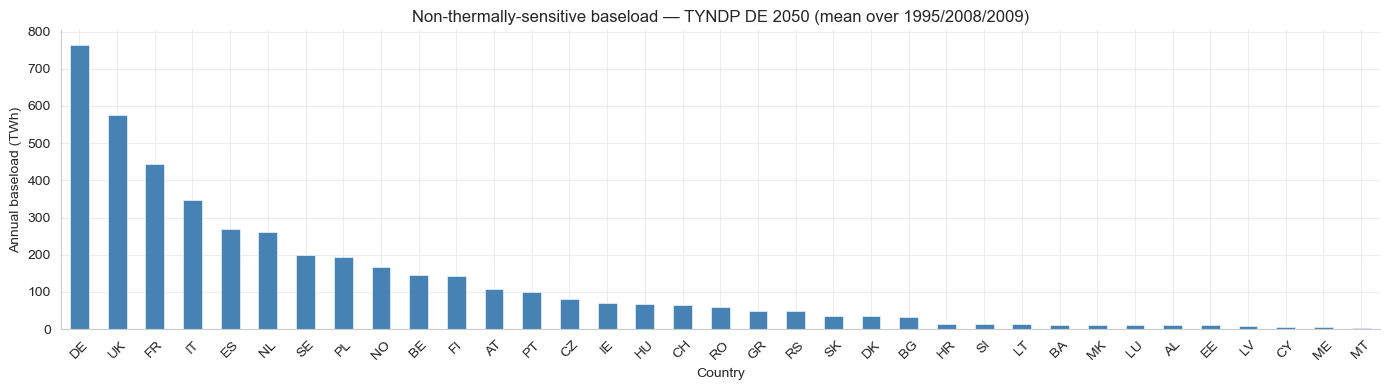

In [31]:
_annual_baseload = (
    (ds_tyndp_baseload_typical.sum("hour_of_year") * 1e-3)
    .baseload.to_series()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(14, 4))
_annual_baseload.plot.bar(ax=ax, color="steelblue", edgecolor="white", linewidth=0.4)
ax.set_xlabel("Country")
ax.set_ylabel("Annual baseload (TWh)")
ax.set_title(
    f"Non-thermally-sensitive baseload — TYNDP {scenario} {year} (mean over 1995/2008/2009)"
)
ax.tick_params(axis="x", rotation=45)
sns.despine()
plt.tight_layout()
plt.show()

In [32]:
ds_thermal_preprocessed

<xarray.Dataset> Size: 80MB
Dimensions:         (country: 37, time: 262990)
Coordinates:
  * country         (country) <U2 296B 'AL' 'AT' 'BE' 'BA' ... 'CH' 'UA' 'UK'
  * time            (time) datetime64[us] 2MB 1991-01-01 ... 2020-12-31T21:00:00
Data variables:
    demand_profile  (country, time) float64 78MB 0.2731 0.27 ... 11.76 11.74

# Compute residual load

In [33]:
ds_residual_load_DE_2050, ds_components_DE_2050 = compute_residual_load(
    ds_gen_pv * 3 * 1e-3,
    ds_gen_wind_on * 3 * 1e-3,
    ds_gen_wind_off * 3 * 1e-3,
    ds_hydro_ror,
    ds_tyndp_baseload_typical,  # typical-year (hour_of_year dim) — auto-expanded
    ds_heating_demand,
    ds_cooling_demand,
    target_twh_per_country=thermal_targets,
    return_generation_demand_components=True,
)

In [35]:
ds_residual_load_DE_2050_zonal = aggregate_by_balancing_zones(ds_residual_load_DE_2050)

In [36]:
ds_components_DE_2050_zonal = aggregate_by_balancing_zones(ds_components_DE_2050)

In [39]:
# test = ds_residual_load_DE_2050_zonal.sel(zone="Central_Western").where(ds_residual_load_DE_2050_zonal.sel(zone="Central_Western") > da_evt_thresholds.sel(zone="Central_Western")).residual_load
for t in ds_residual_load_DE_2050_zonal.time:
    if ds_residual_load_DE_2050_zonal.sel(zone="Central_Western").sel(time=t).residual_load.values > 300:
        print(t, ds_residual_load_DE_2050_zonal.sel(zone="Central_Western").sel(time=t).values)
        break

<xarray.DataArray 'time' ()> Size: 8B
array('1991-01-02T06:00:00.000000', dtype='datetime64[us]')
Coordinates:
    time     datetime64[us] 8B 1991-01-02T06:00:00 <bound method Mapping.values of <xarray.Dataset> Size: 76B
Dimensions:        ()
Coordinates:
    time           datetime64[us] 8B 1991-01-02T06:00:00
    zone           <U15 60B 'Central_Western'
Data variables:
    residual_load  float64 8B 414.7
Attributes:
    description:  Residual load = total demand − (PV + onshore wind + offshor...>


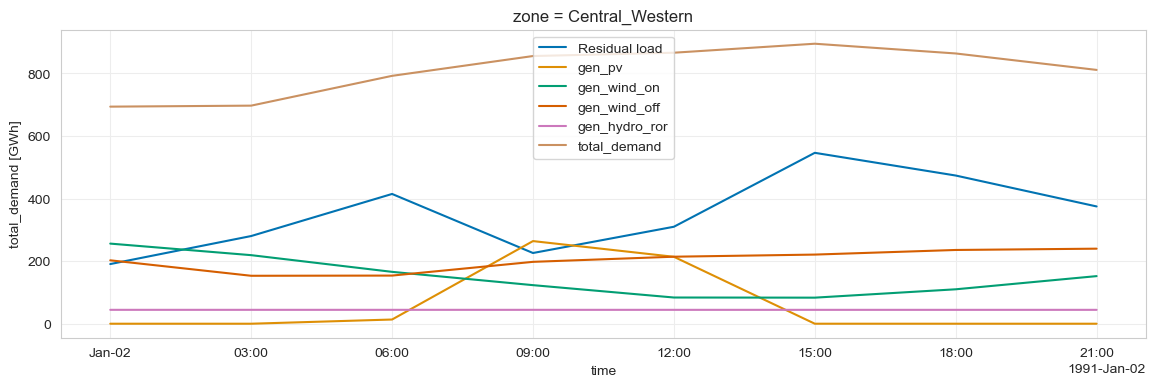

In [40]:
fig, ax = plt.subplots(figsize=(14, 4))
ds_residual_load_DE_2050_zonal.sel(time="1991-01-02", zone="Central_Western").residual_load.plot(ax=ax, label="Residual load")
for var in ds_components_DE_2050_zonal.data_vars:
    ds_components_DE_2050_zonal[var].sel(zone="Central_Western", time="1991-01-02").plot(
        ax=ax, label=var
    )
ax.legend()
plt.show()

## Diagnostics — Central Western residual load components

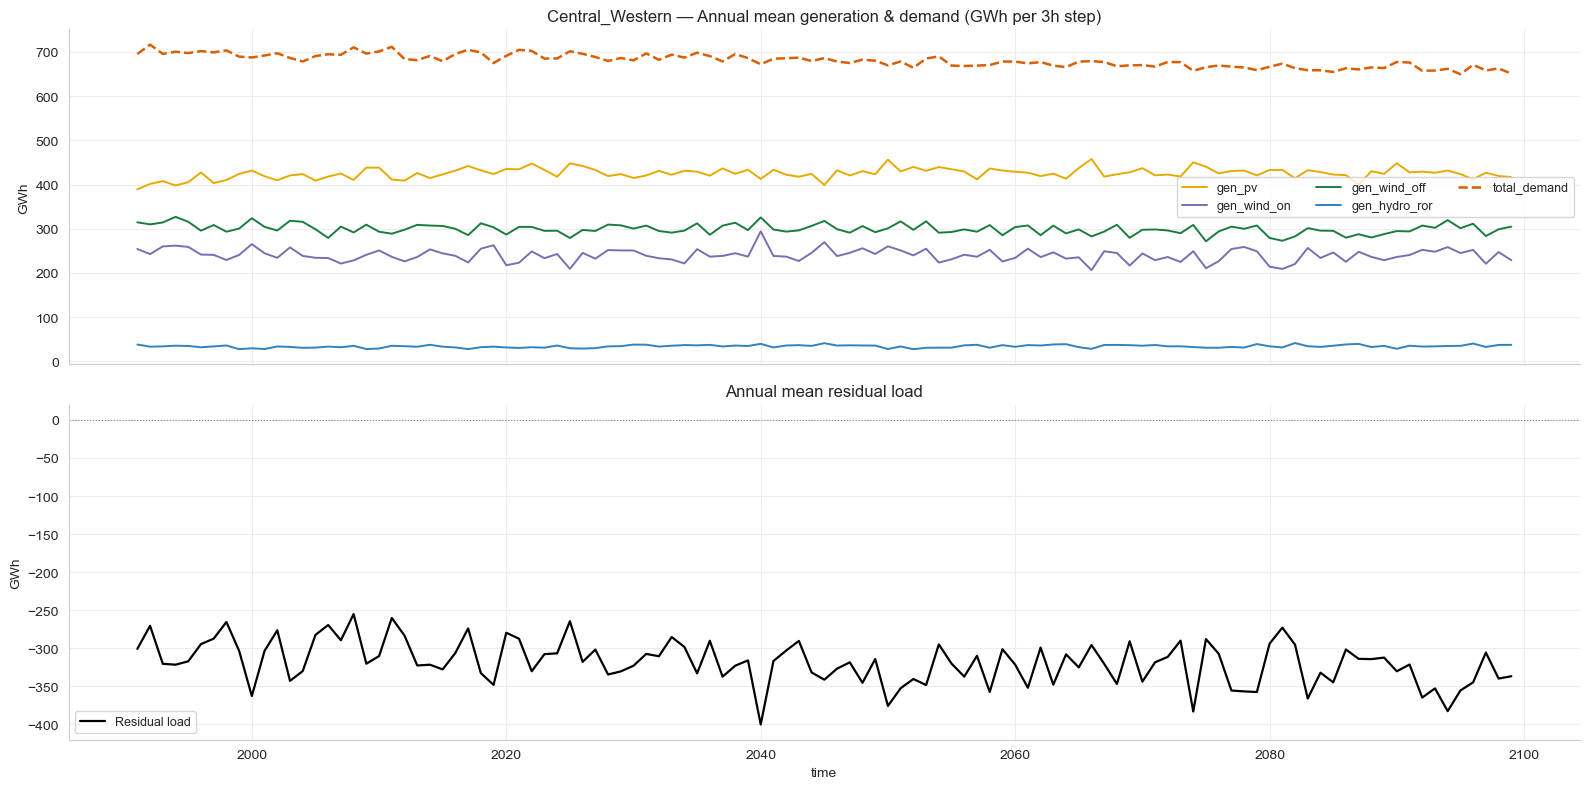

In [46]:
ZONE = "Central_Western"

ds_rl_cw   = ds_residual_load_DE_2050_zonal.sel(zone=ZONE)
ds_comp_cw = ds_components_DE_2050_zonal.sel(zone=ZONE)

comp_vars   = list(ds_comp_cw.data_vars)          # e.g. total_demand, gen_pv, …
gen_vars    = [v for v in comp_vars if v.startswith("gen_")]
demand_vars = [v for v in comp_vars if "demand" in v]

# ── colour map ───────────────────────────────────────────────────────────────
_palette = {
    "gen_pv":        "#E6AB02",
    "gen_wind_on":   "#7570B3",
    "gen_wind_off":  "#1B7C3D",
    "gen_hydro_ror": "#3182BD",
    "total_demand":  "#D95F02",
    "residual_load": "black",
}

# ── helper: annual mean resampling ───────────────────────────────────────────
def annual_mean(da):
    return da.resample(time="YS").mean()

def annual_sum(da):
    return da.resample(time="YS").sum()

# ── 1. Full time-series overview (annual means) ──────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

ax = axes[0]
for v in gen_vars:
    annual_mean(ds_comp_cw[v]).plot(ax=ax, label=v, color=_palette.get(v), lw=1.4)
annual_mean(ds_comp_cw["total_demand"]).plot(
    ax=ax, label="total_demand", color=_palette["total_demand"], lw=1.8, ls="--"
)
ax.set_title(f"{ZONE} — Annual mean generation & demand (GWh per 3h step)", fontsize=12)
ax.set_ylabel("GWh")
ax.legend(ncol=3, fontsize=9)
ax.set_xlabel("")

ax = axes[1]
annual_mean(ds_rl_cw["residual_load"]).plot(
    ax=ax, color=_palette["residual_load"], lw=1.6, label="Residual load"
)
ax.axhline(0, color="grey", lw=0.8, ls=":")
ax.set_title("Annual mean residual load", fontsize=12)
ax.set_ylabel("GWh")
ax.legend(fontsize=9)

sns.despine()
plt.tight_layout()
plt.show()


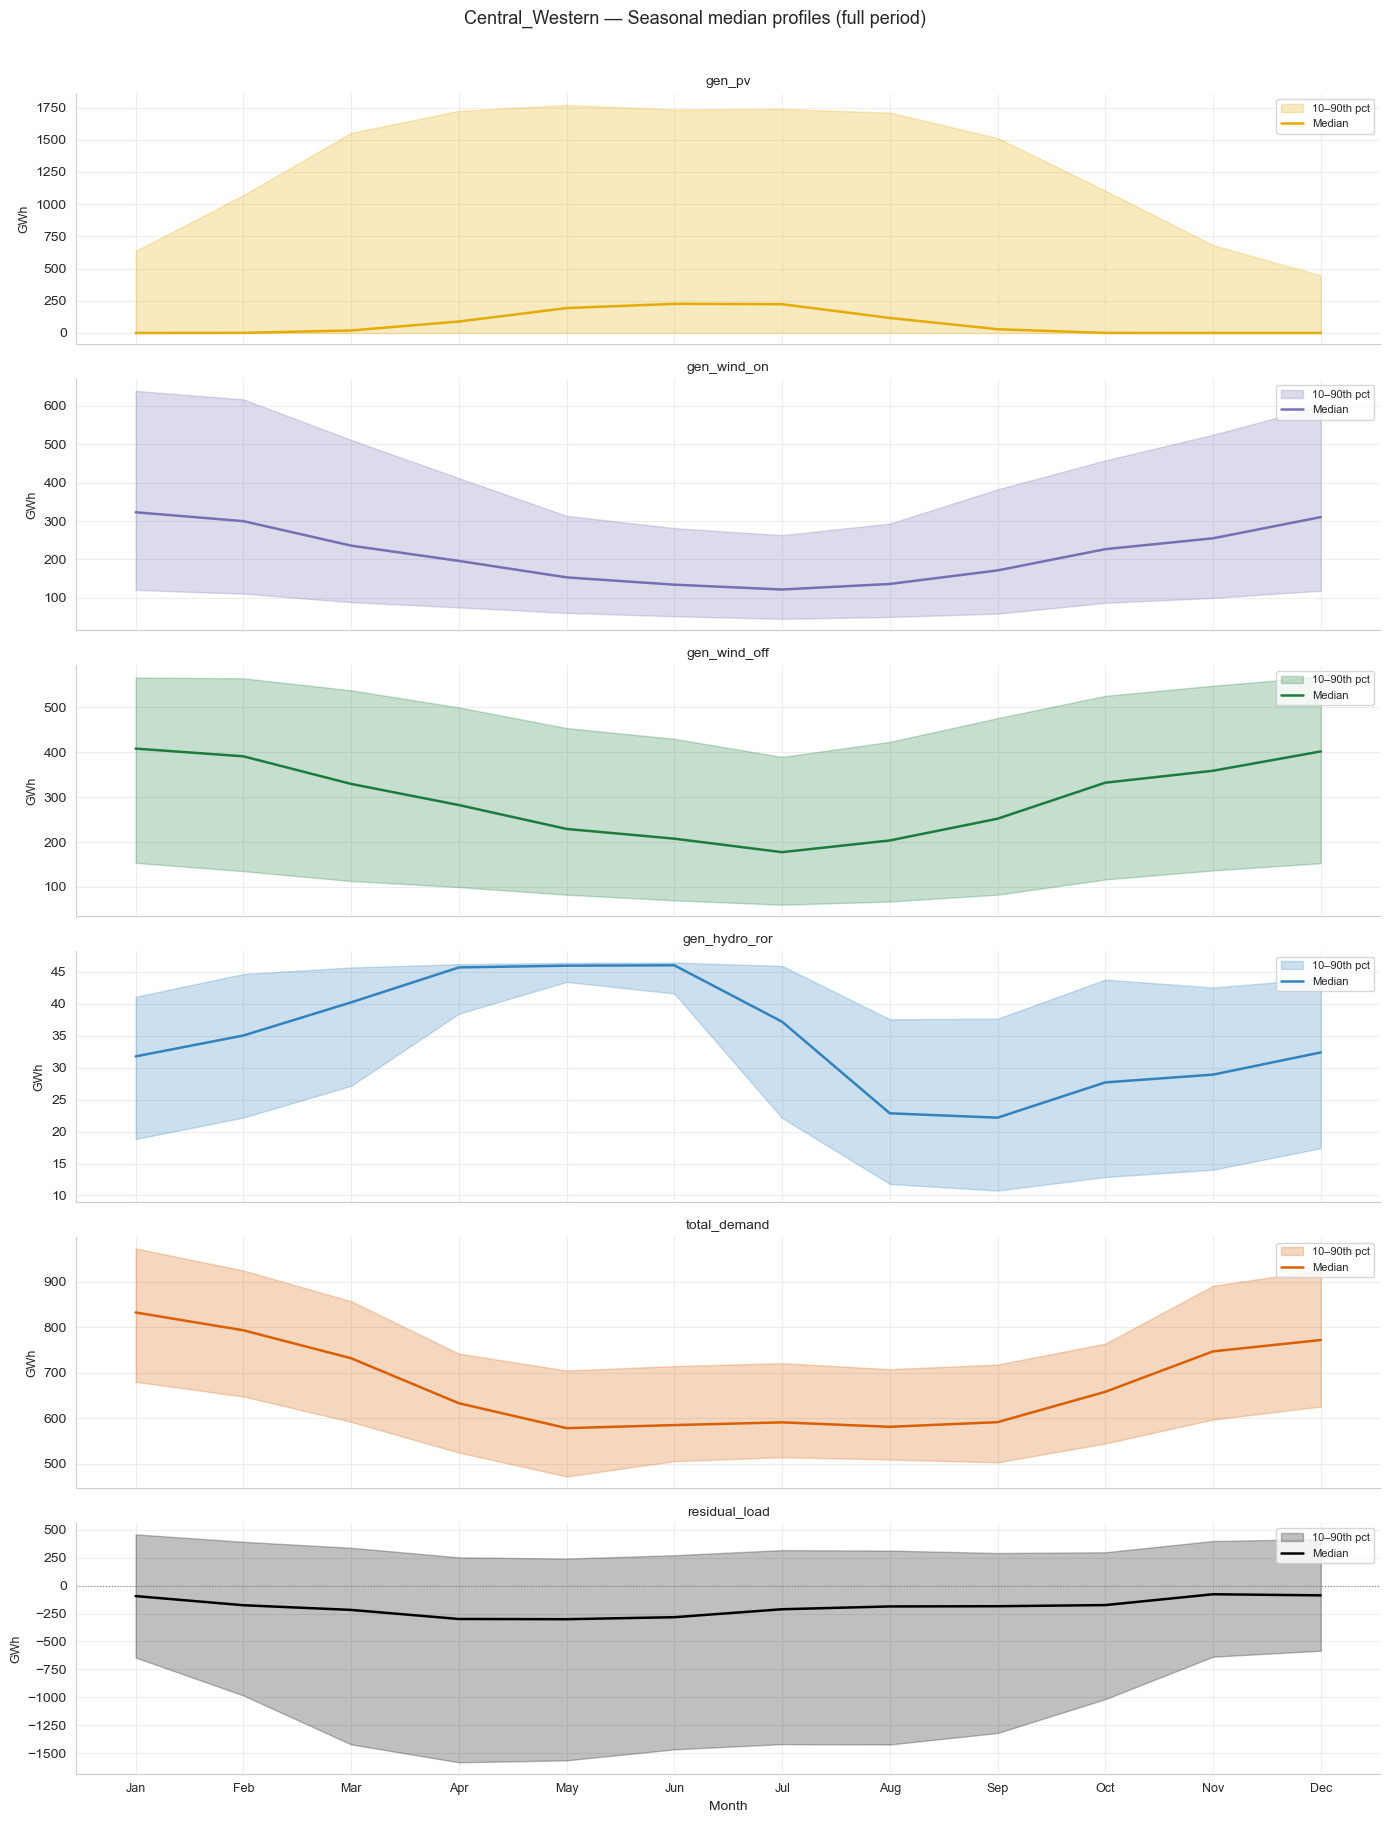

In [47]:
# ── 2. Seasonal cycle — median 3-hourly profiles by month ────────────────────
#    For each component and the residual load, compute the median value grouped
#    by month across the full simulation period.

fig, axes = plt.subplots(len(comp_vars) + 1, 1, figsize=(14, 3 * (len(comp_vars) + 1)), sharex=True)

all_vars = comp_vars + ["residual_load"]
all_ds   = {v: ds_comp_cw[v] for v in comp_vars}
all_ds["residual_load"] = ds_rl_cw["residual_load"]

for ax, v in zip(axes, all_vars):
    da = all_ds[v]
    monthly_median = da.groupby("time.month").median()
    monthly_q10    = da.groupby("time.month").quantile(0.10)
    monthly_q90    = da.groupby("time.month").quantile(0.90)

    months = monthly_median.month.values
    color  = _palette.get(v, "steelblue")

    ax.fill_between(months, monthly_q10.values, monthly_q90.values,
                    alpha=0.25, color=color, label="10–90th pct")
    ax.plot(months, monthly_median.values, color=color, lw=1.8, label="Median")
    if v == "residual_load":
        ax.axhline(0, color="grey", lw=0.8, ls=":")
    ax.set_ylabel("GWh", fontsize=9)
    ax.set_title(v, fontsize=10)
    ax.legend(fontsize=8, loc="upper right")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun",
                         "Jul","Aug","Sep","Oct","Nov","Dec"], fontsize=9)

axes[-1].set_xlabel("Month")
fig.suptitle(f"{ZONE} — Seasonal median profiles (full period)", fontsize=13, y=1.01)
sns.despine()
plt.tight_layout()
plt.show()


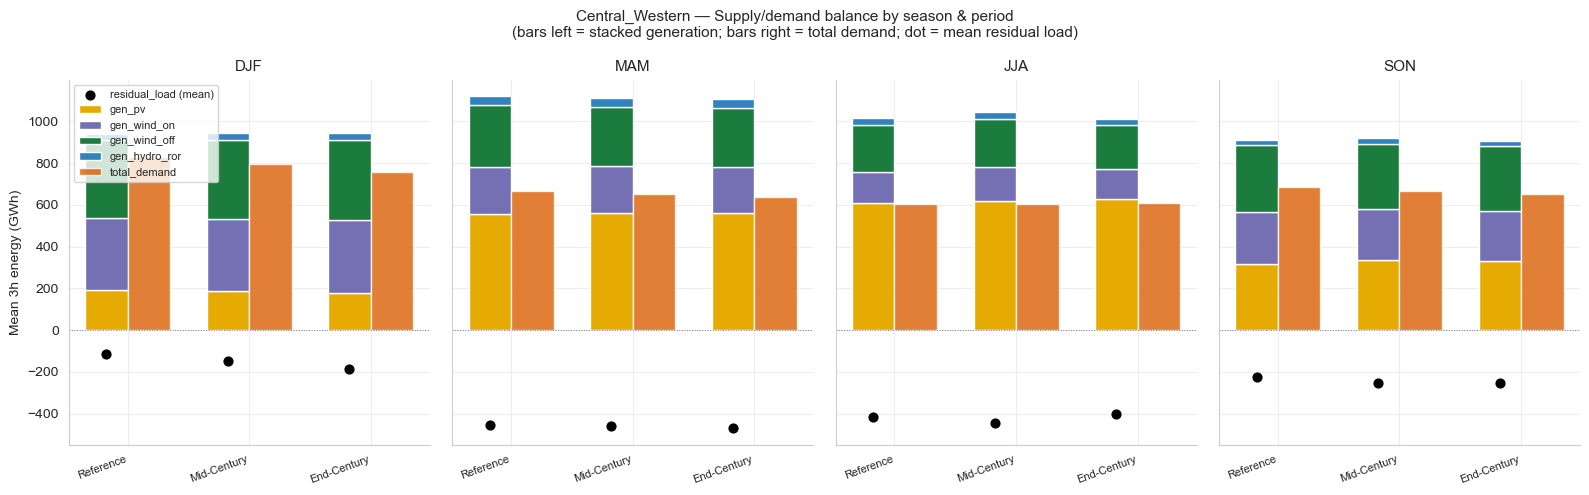

In [48]:
# ── 3. Supply–demand balance stacked bar by season × period ──────────────────
#    Shows where the residual load is coming from: how much total demand exceeds
#    the sum of all generation assets, per ERA and per season.

periods = {
    "Reference":    slice(REFERENCE_PERIOD[0],    REFERENCE_PERIOD[1]),
    "Mid-Century":  slice(MID_CENTURY_PERIOD[0],  MID_CENTURY_PERIOD[1]),
    "End-Century":  slice(END_CENTURY_PERIOD[0],  END_CENTURY_PERIOD[1]),
}
season_map = {3: "MAM", 4: "MAM", 5: "MAM",
              6: "JJA", 7: "JJA", 8: "JJA",
              9: "SON", 10: "SON", 11: "SON",
              12: "DJF", 1: "DJF", 2: "DJF"}

records = []
for period_name, sl in periods.items():
    ds_p = ds_comp_cw.sel(time=sl)
    rl_p = ds_rl_cw["residual_load"].sel(time=sl)
    months = ds_p.time.dt.month.values
    season_labels = [season_map[m] for m in months]

    for season in ["DJF", "MAM", "JJA", "SON"]:
        mask = np.array(season_labels) == season
        rec = {"Period": period_name, "Season": season}
        for v in gen_vars:
            rec[v] = float(ds_p[v].values[mask].mean())
        rec["total_demand"] = float(ds_p["total_demand"].values[mask].mean())
        rec["residual_load"] = float(rl_p.values[mask].mean())
        # total_generation as diagnostic
        rec["total_gen"] = sum(float(ds_p[v].values[mask].mean()) for v in gen_vars)
        records.append(rec)

df_seasonal = pd.DataFrame(records)

fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)
season_order = ["DJF", "MAM", "JJA", "SON"]
period_colors = {"Reference": "#4A90E2", "Mid-Century": "#F5A623", "End-Century": "#E24A4A"}

for ax, season in zip(axes, season_order):
    df_s = df_seasonal[df_seasonal["Season"] == season].set_index("Period")

    x = np.arange(len(periods))
    width = 0.35

    # Stacked generation bars
    bottoms = np.zeros(3)
    for v in gen_vars:
        vals = [df_s.loc[p, v] for p in periods]
        ax.bar(x - width / 2, vals, width, bottom=bottoms,
               color=_palette.get(v), label=v if season == "DJF" else "")
        bottoms += np.array(vals)

    # Demand bars
    demand_vals = [df_s.loc[p, "total_demand"] for p in periods]
    ax.bar(x + width / 2, demand_vals, width,
           color=_palette["total_demand"], alpha=0.8,
           label="total_demand" if season == "DJF" else "")

    # Residual load dots
    rl_vals = [df_s.loc[p, "residual_load"] for p in periods]
    ax.scatter(x - width / 2, rl_vals, color="black", zorder=5, s=40,
               label="residual_load (mean)" if season == "DJF" else "")

    ax.set_xticks(x)
    ax.set_xticklabels(list(periods.keys()), rotation=20, ha="right", fontsize=8)
    ax.set_title(season, fontsize=11)
    ax.axhline(0, color="grey", lw=0.7, ls=":")

axes[0].set_ylabel("Mean 3h energy (GWh)", fontsize=10)
fig.suptitle(f"{ZONE} — Supply/demand balance by season & period\n"
             f"(bars left = stacked generation; bars right = total demand; dot = mean residual load)",
             fontsize=11)
axes[0].legend(fontsize=8, loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()


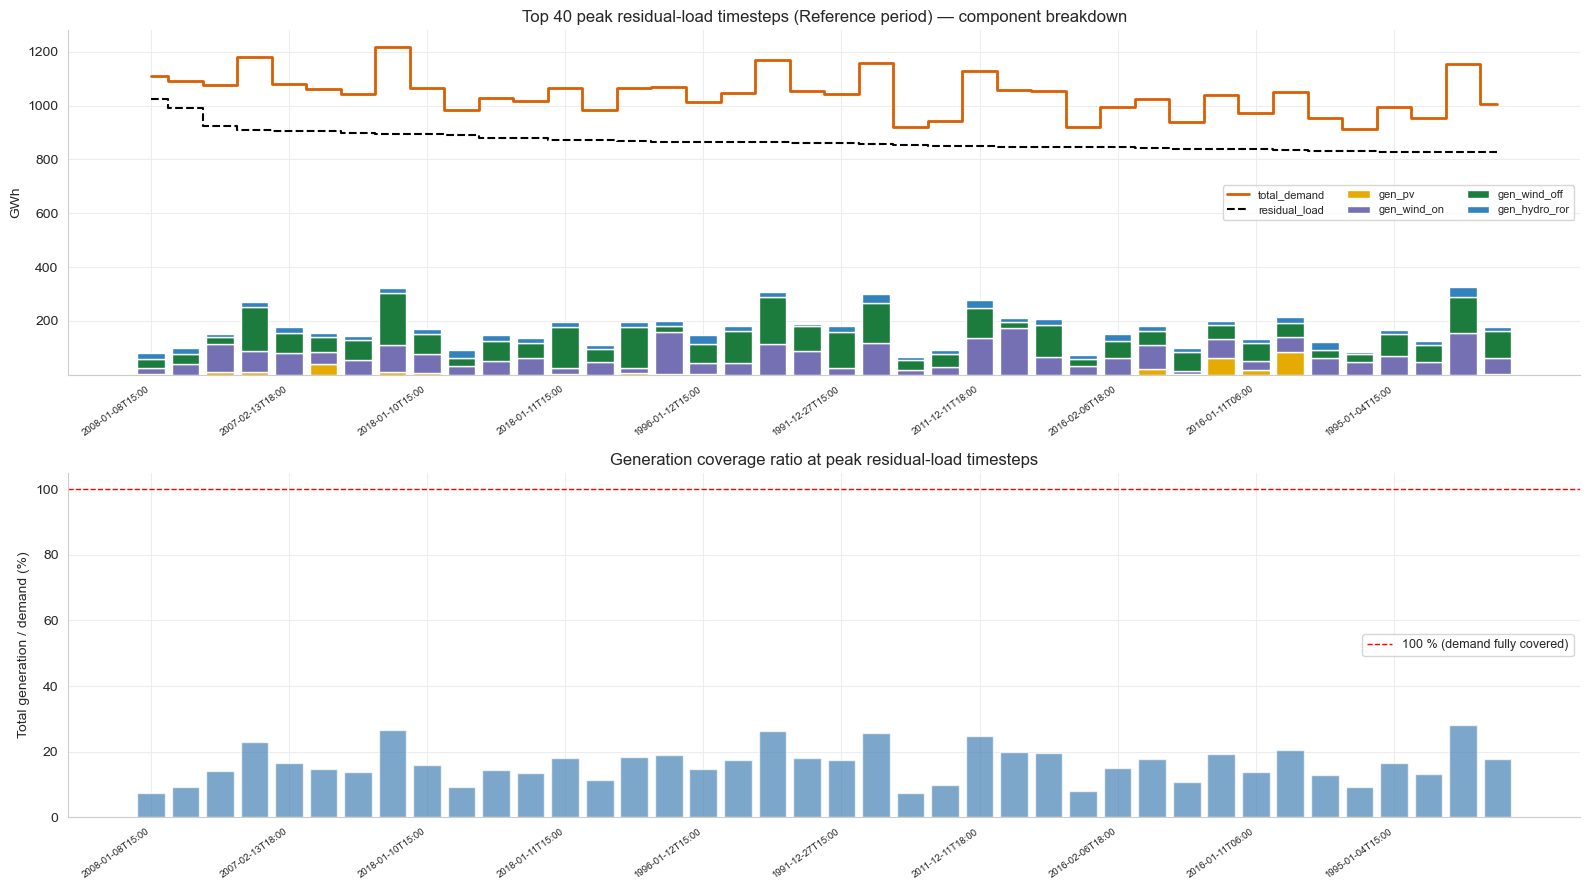

In [49]:
# ── 4. Top-N extreme events: component breakdown ─────────────────────────────
#    For the reference period, find the N 3-hourly timesteps with the highest
#    residual load and show a stacked bar of each component.

N_TOP = 40
rl_ref = ds_rl_cw["residual_load"].sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))
comp_ref = ds_comp_cw.sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))

top_idx = rl_ref.argsort()[-N_TOP:].values[::-1]   # indices of N largest
top_times = rl_ref.time.values[top_idx]

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

# --- top panel: stacked generation vs demand at peak timesteps ---
ax = axes[0]
x = np.arange(N_TOP)
bottoms = np.zeros(N_TOP)
for v in gen_vars:
    vals = comp_ref[v].values[top_idx]
    ax.bar(x, vals, bottom=bottoms, label=v, color=_palette.get(v), width=0.8)
    bottoms += vals

demand_vals = comp_ref["total_demand"].values[top_idx]
ax.step(x, demand_vals, where="mid", color=_palette["total_demand"],
        lw=2, label="total_demand")
rl_vals = rl_ref.values[top_idx]
ax.step(x, rl_vals, where="mid", color="black", lw=1.5, ls="--", label="residual_load")

ax.set_xticks(x[::4])
ax.set_xticklabels(
    [str(t)[:16] for t in top_times[::4]], rotation=35, ha="right", fontsize=7
)
ax.set_ylabel("GWh")
ax.set_title(f"Top {N_TOP} peak residual-load timesteps (Reference period) — component breakdown")
ax.legend(ncol=3, fontsize=8)
ax.axhline(0, color="grey", lw=0.7, ls=":")

# --- bottom panel: ratio total_gen / total_demand at those peaks ---
ax2 = axes[1]
total_gen_at_peaks = np.array([
    sum(comp_ref[v].values[top_idx] for v in gen_vars)
])
ratio = (total_gen_at_peaks / demand_vals).squeeze()
ax2.bar(x, ratio * 100, color="steelblue", alpha=0.7, width=0.8)
ax2.axhline(100, color="red", lw=1, ls="--", label="100 % (demand fully covered)")
ax2.set_ylabel("Total generation / demand (%)")
ax2.set_title("Generation coverage ratio at peak residual-load timesteps")
ax2.set_xticks(x[::4])
ax2.set_xticklabels(
    [str(t)[:16] for t in top_times[::4]], rotation=35, ha="right", fontsize=7
)
ax2.legend(fontsize=9)

sns.despine()
plt.tight_layout()
plt.show()


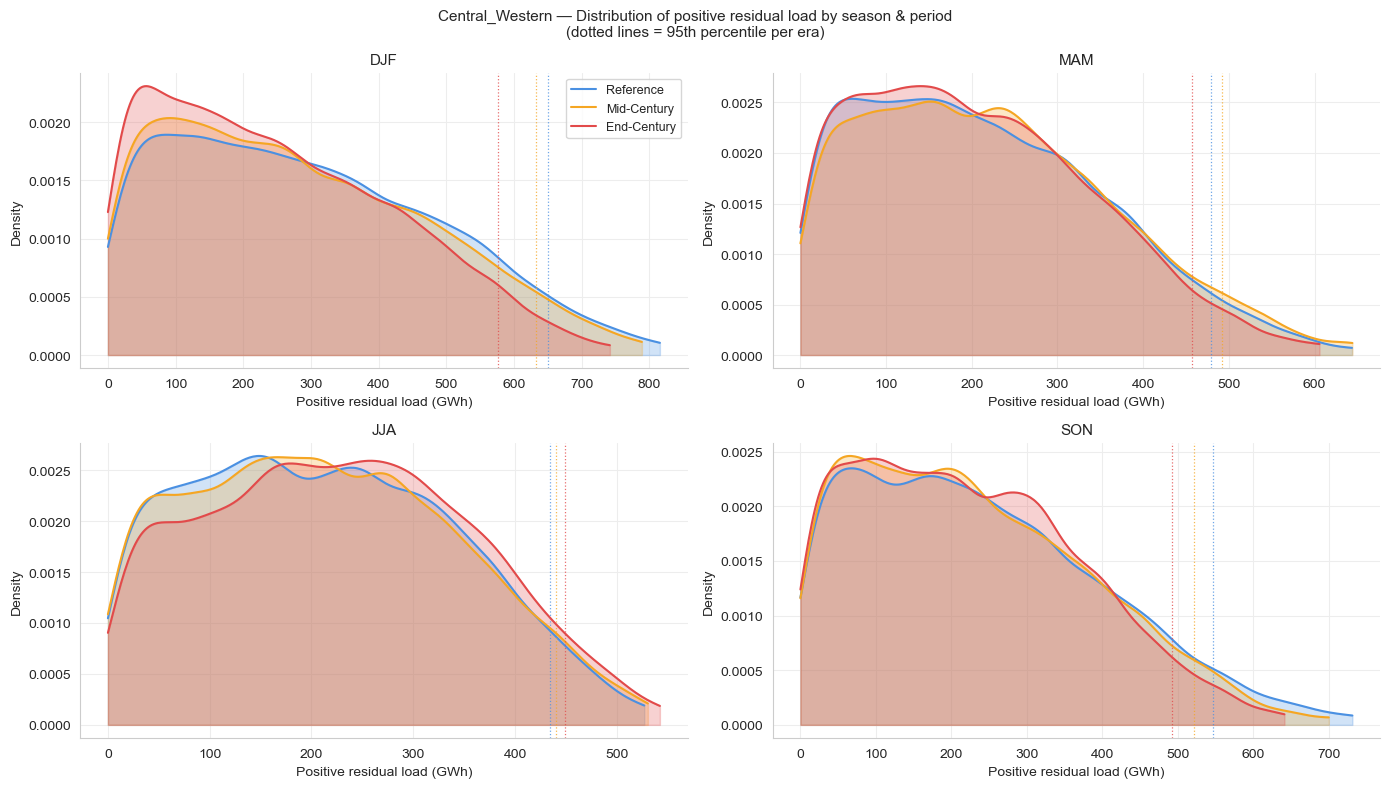


── Mean positive residual load (GWh per 3h step) ─────────────────────
  DJF   Reference: 296.8 (p99=775.3)  |  Mid-Century: 284.0 (p99=749.2)  |  End-Century: 255.2 (p99=693.5)
  MAM   Reference: 217.9 (p99=590.1)  |  Mid-Century: 224.9 (p99=602.1)  |  End-Century: 209.9 (p99=566.6)
  JJA   Reference: 215.1 (p99=504.3)  |  Mid-Century: 216.0 (p99=508.8)  |  End-Century: 229.7 (p99=519.4)
  SON   Reference: 242.1 (p99=685.5)  |  Mid-Century: 233.1 (p99=645.3)  |  End-Century: 226.2 (p99=605.4)


In [50]:
# ── 5. Residual load distribution by season & period ────────────────────────
#    KDE + rug of positive residual load split by season; each era overlaid.

from scipy.stats import gaussian_kde

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, season in zip(axes, season_order):
    for period_name, sl in periods.items():
        rl_p = ds_rl_cw["residual_load"].sel(time=sl)
        months = rl_p.time.dt.month.values
        mask = np.array([season_map[m] for m in months]) == season
        pos_rl = rl_p.values[mask]
        pos_rl = pos_rl[pos_rl > 0]
        if len(pos_rl) < 10:
            continue
        color = period_colors[period_name]
        kde = gaussian_kde(pos_rl, bw_method=0.15)
        xs = np.linspace(0, np.percentile(pos_rl, 99.5), 300)
        ax.fill_between(xs, kde(xs), alpha=0.25, color=color)
        ax.plot(xs, kde(xs), color=color, lw=1.5, label=period_name)
        # Mark 95th percentile
        p95 = np.percentile(pos_rl, 95)
        ax.axvline(p95, color=color, lw=0.9, ls=":", alpha=0.8)

    ax.set_title(season, fontsize=11)
    ax.set_xlabel("Positive residual load (GWh)")
    ax.set_ylabel("Density")

axes[0].legend(fontsize=9)
fig.suptitle(
    f"{ZONE} — Distribution of positive residual load by season & period\n"
    "(dotted lines = 95th percentile per era)",
    fontsize=11,
)
sns.despine()
plt.tight_layout()
plt.show()

# ── 6. Summary table: mean & 99th pct positive RL per season × period ─────────
print("\n── Mean positive residual load (GWh per 3h step) ─────────────────────")
for season in season_order:
    row = []
    for period_name, sl in periods.items():
        rl_p = ds_rl_cw["residual_load"].sel(time=sl)
        months = rl_p.time.dt.month.values
        mask = np.array([season_map[m] for m in months]) == season
        pos_rl = rl_p.values[mask]
        pos_rl = pos_rl[pos_rl > 0]
        row.append(f"{np.mean(pos_rl):.1f} (p99={np.percentile(pos_rl, 99):.1f})")
    print(f"  {season:4s}  {'  |  '.join(f'{p}: {v}' for p, v in zip(periods, row))}")


## Additional Diagnostics

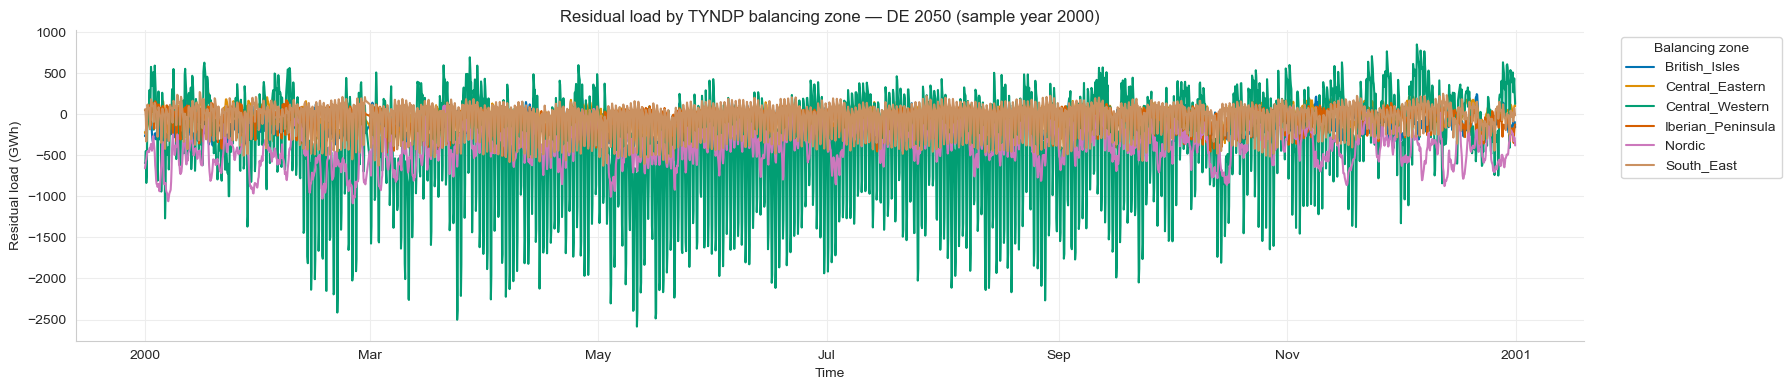

In [51]:
fig, ax = plt.subplots(figsize=(18, 4))
for zone in ds_residual_load_DE_2050_zonal.zone.values:
    ds_residual_load_DE_2050_zonal.sel(zone=zone, time="2000").residual_load.plot(
        ax=ax, label=zone
    )
ax.set_xlabel("Time")
ax.set_ylabel("Residual load (GWh)")
ax.set_title(
    f"Residual load by TYNDP balancing zone — {scenario} {year} (sample year 2000)"
)
ax.legend(title="Balancing zone", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

In [52]:
upper_quantile = {}
for zone in ds_residual_load_DE_2050_zonal.zone.values:
    upper_quantile[zone] = (
        ds_residual_load_DE_2050_zonal.sel(
            zone=zone, time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1])
        )
        .residual_load.where(
            ds_residual_load_DE_2050_zonal.sel(
                zone=zone, time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1])
            ).residual_load
            > 0
        )
        .quantile(0.99)
        .values
    )
    print(
        f"{zone}: 99th percentile of positive residual load = {upper_quantile[zone]:.2f} GWh"
    )

British_Isles: 99th percentile of positive residual load = 214.74 GWh
Central_Eastern: 99th percentile of positive residual load = 214.36 GWh
Central_Western: 99th percentile of positive residual load = 705.35 GWh
Iberian_Peninsula: 99th percentile of positive residual load = 139.93 GWh
Nordic: 99th percentile of positive residual load = 152.72 GWh
South_East: 99th percentile of positive residual load = 215.58 GWh


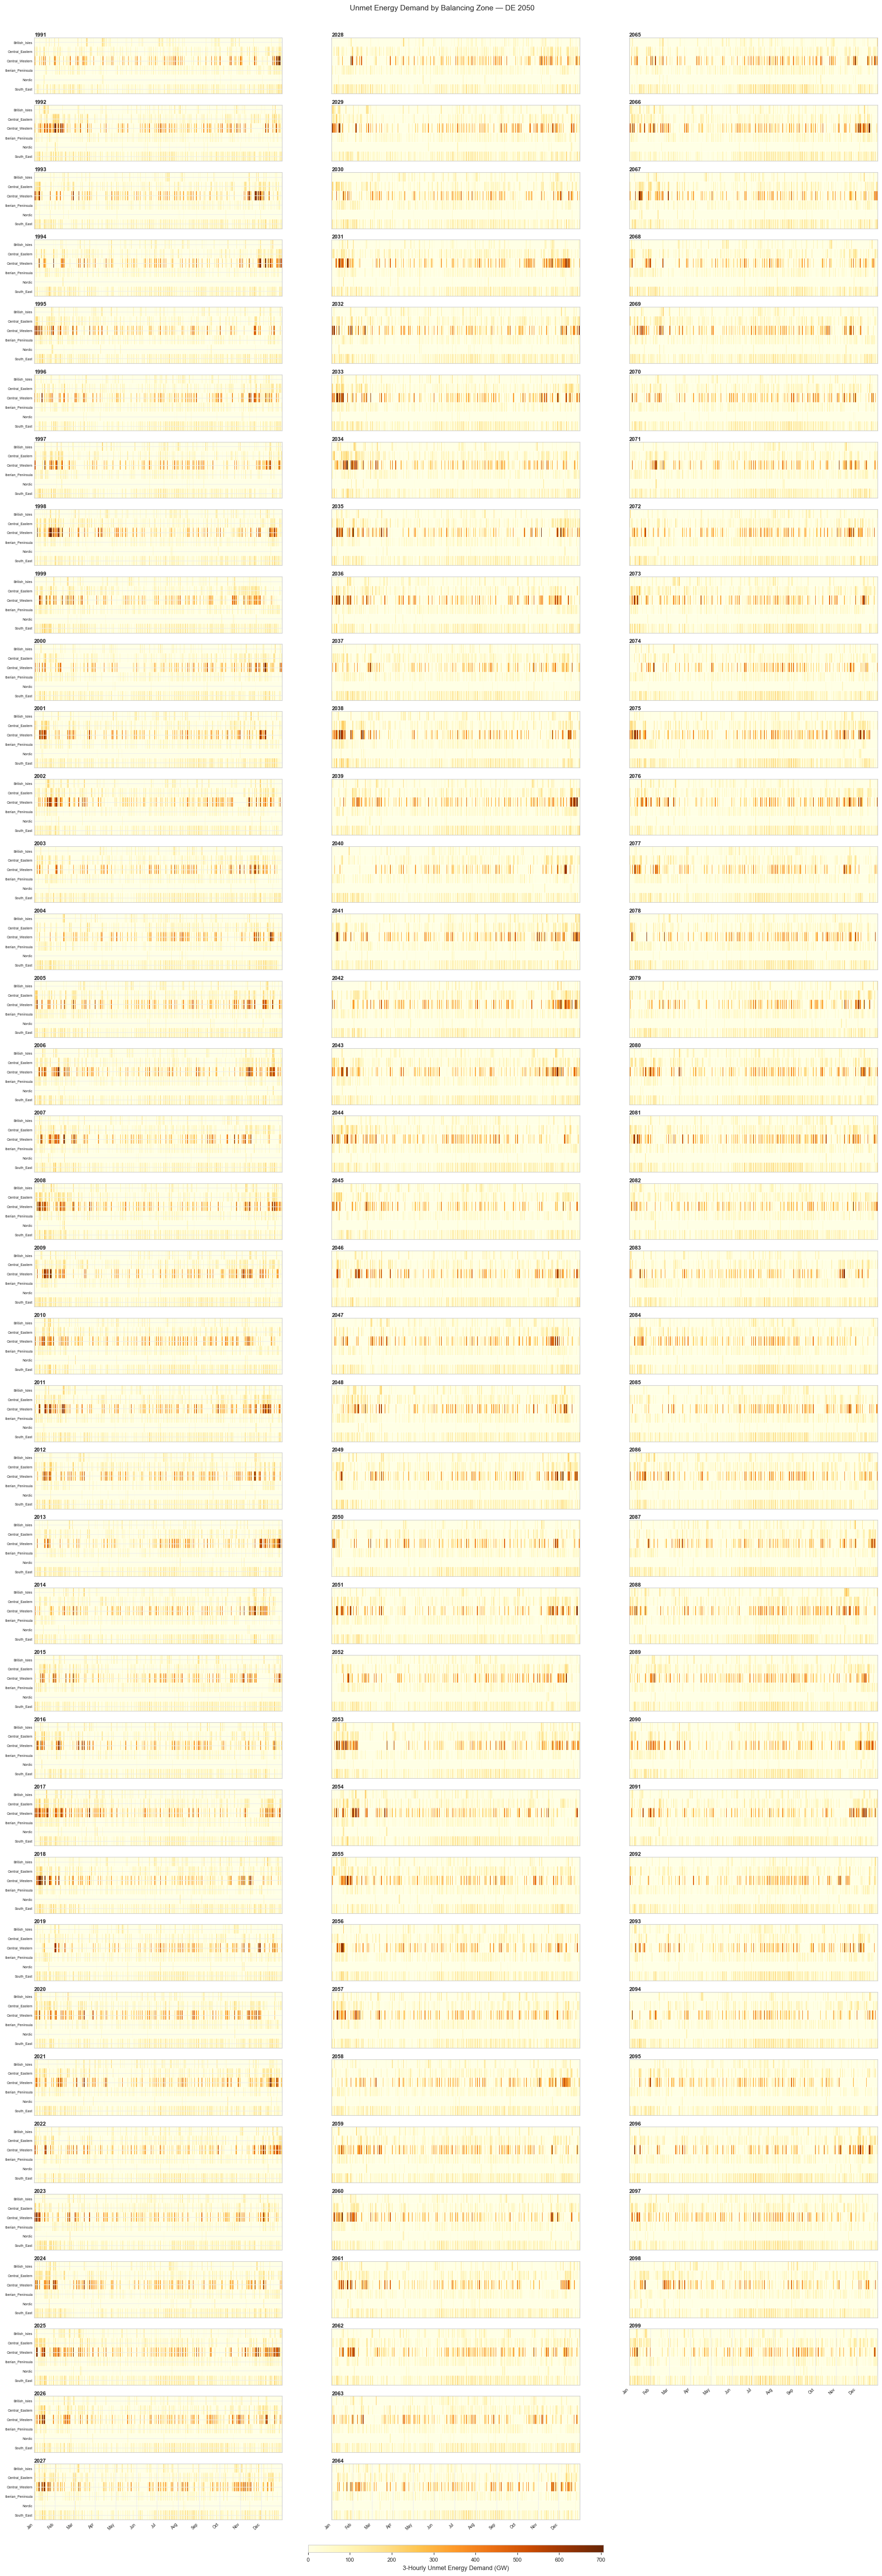

In [53]:
fig_unmet = plot_unmet_demand_overview(
    ds_residual_load_DE_2050_zonal,
    # ((ds_residual_load_DE_2050_zonal / ds_components_DE_2050_zonal.total_demand) * 100).clip(
    #     min=0
    # ),
    vmax=max(upper_quantile.values()),
    # vmax=100,
    suptitle=f"Unmet Energy Demand by Balancing Zone — {scenario} {year}",
    # cbar_label="Unmet demand (% of total demand)",
)
# plt.savefig(path_data_extremes / f"unmet_demand_overview_{scenario}_{year}.png",
#             dpi=150, bbox_inches="tight")
plt.show()

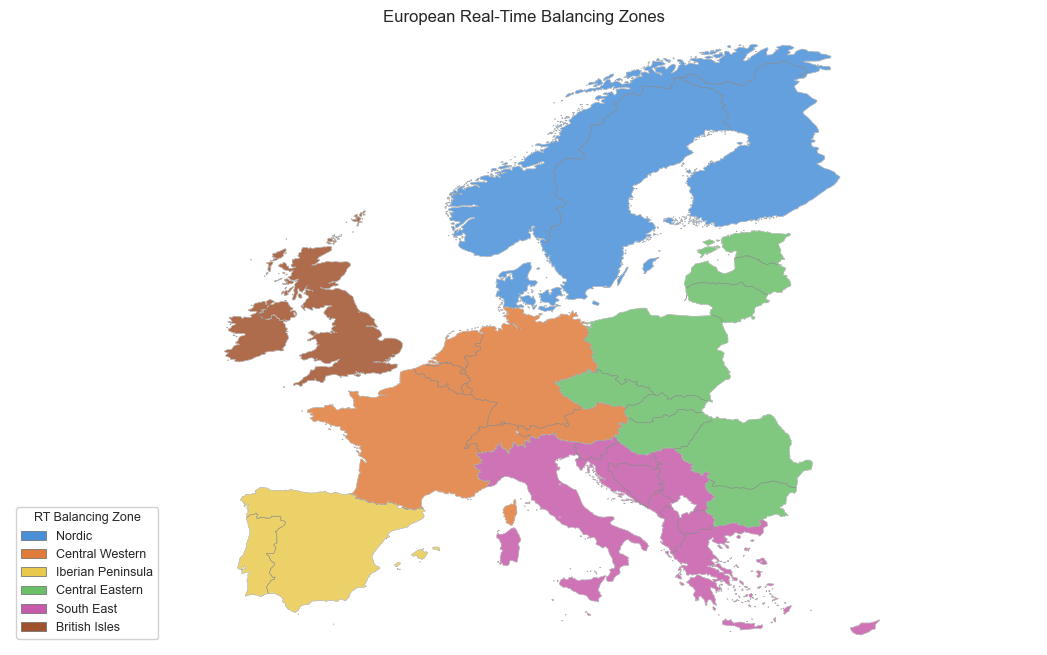

In [ ]:
import geopandas as gpd
from matplotlib.patches import Patch

from cordex2energy.conversion_energy.tyndp import REALTIME_BALANCING_ZONES

# Build inverted lookup: ISO2 → zone name
country_to_rtbz = {
    country: zone
    for zone, countries in REALTIME_BALANCING_ZONES.items()
    for country in countries
}

# Derive ISO2 from the TYNDP bidding zone code (first two chars: FR00 → FR)
gdf_tz = build_tyndp_zone_geometries(
    tyndp_nuts2_mapping, df_tyndp_nuts_mapping, gdf_nuts2, gdf_uk_nuts1
)
gdf_tz = gdf_tyndp_zones.copy()  # drop zones with no geometry
gdf_tz["iso2"] = gdf_tz["tyndp_zone"].str[:2]
gdf_tz["rtbz"] = gdf_tz["iso2"].map(country_to_rtbz)

# Dissolve to RT balancing zone polygons (union of all bidding-zone geometries per zone)
gdf_rtbz = (
    gdf_tz.dropna(subset=["rtbz"])
    .dissolve(by="rtbz")
    .reset_index()[["rtbz", "geometry"]]
)

palette = {
    "Nordic": "#4a90d9",
    "Central_Western": "#e07b39",
    "Iberian_Peninsula": "#e8c94e",
    "Central_Eastern": "#6abf69",
    "South_East": "#c75bab",
    "British_Isles": "#a0522d",
}
gdf_rtbz["color"] = gdf_rtbz["rtbz"].map(palette)

fig, ax = plt.subplots(figsize=(11, 9))

# Fill each zone
gdf_rtbz.plot(
    ax=ax, color=gdf_rtbz["color"], edgecolor="white", linewidth=0.4, alpha=0.85
)

# Thin country-level borders on top
gdf_tz.dissolve(by="iso2").reset_index().plot(
    ax=ax,
    facecolor="none",
    edgecolor="0.55",
    linewidth=0.3,
)

# Legend
legend_handles = [
    Patch(
        facecolor=palette[z], edgecolor="0.4", linewidth=0.5, label=z.replace("_", " ")
    )
    for z in REALTIME_BALANCING_ZONES
]
ax.legend(
    handles=legend_handles,
    title="RT Balancing Zone",
    loc="lower left",
    fontsize=9,
    title_fontsize=9,
    framealpha=0.9,
)

ax.set_xlim(-25, 45)
ax.set_ylim(34, 72)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("European Real-Time Balancing Zones", fontsize=12)
sns.despine(left=False, bottom=False)
plt.tight_layout()
ax.axis("off")
plt.show()

# Find extremes

In [ ]:
compute_evt_thresholds_for_all_zones(
    ds_residual_load_DE_2050_zonal.sel(
        time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1])
    ).residual_load
)

<xarray.DataArray 'evt_threshold' (zone: 6)> Size: 48B
array([185.74904185, 194.45023373, 624.53545675, 127.31980079,
       137.1606211 , 196.55424784])
Coordinates:
  * zone     (zone) <U17 408B 'British_Isles' 'Central_Eastern' ... 'South_East'

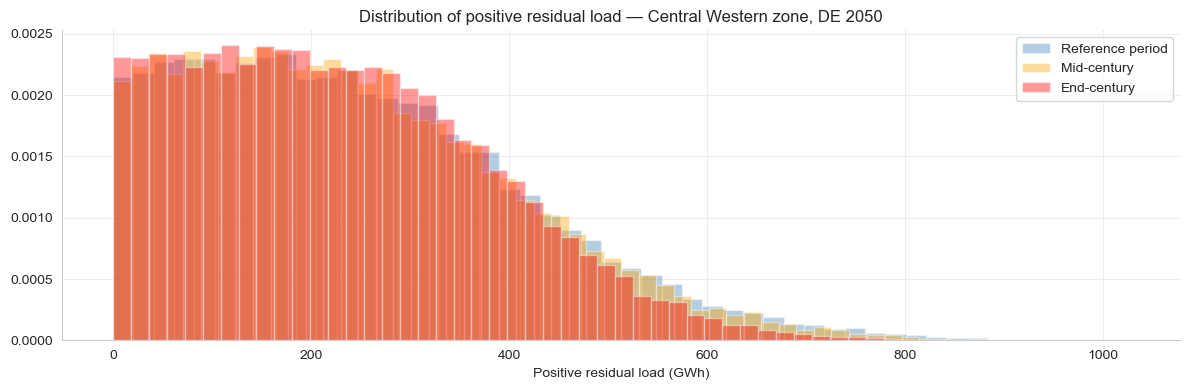

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
(
    ds_residual_load_DE_2050_zonal.sel(
        zone="Central_Western", time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1])
    ).residual_load.where(
        ds_residual_load_DE_2050_zonal.sel(
            zone="Central_Western", time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1])
        ).residual_load
        > 0
    )
).plot.hist(
    ax=ax, bins=50, density=True, color="steelblue", alpha=0.4, label="Reference period"
)

(
    ds_residual_load_DE_2050_zonal.sel(
        zone="Central_Western", time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1])
    ).residual_load.where(
        ds_residual_load_DE_2050_zonal.sel(
            zone="Central_Western",
            time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]),
        ).residual_load
        > 0
    )
).plot.hist(
    ax=ax, bins=50, density=True, color="orange", alpha=0.4, label="Mid-century"
)

(
    ds_residual_load_DE_2050_zonal.sel(
        zone="Central_Western", time=slice(END_CENTURY_PERIOD[0], END_CENTURY_PERIOD[1])
    ).residual_load.where(
        ds_residual_load_DE_2050_zonal.sel(
            zone="Central_Western",
            time=slice(END_CENTURY_PERIOD[0], END_CENTURY_PERIOD[1]),
        ).residual_load
        > 0
    )
).plot.hist(ax=ax, bins=50, density=True, color="red", alpha=0.4, label="End-century")

plt.xlabel("Positive residual load (GWh)")
plt.title(
    f"Distribution of positive residual load — Central Western zone, {scenario} {year}"
)
plt.legend()
sns.despine()
plt.tight_layout()
plt.show()

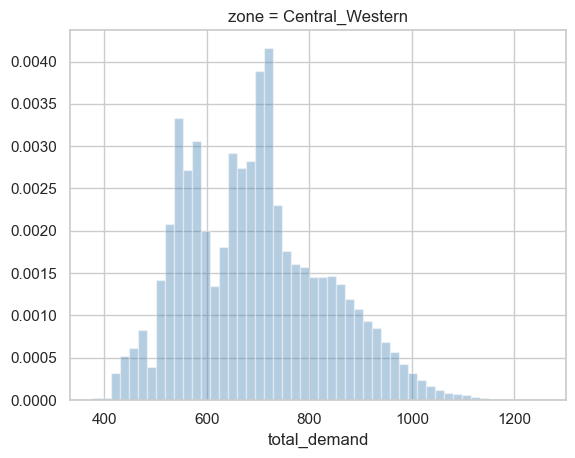

In [144]:
ds_components_DE_2050_zonal.total_demand.sel(zone="Central_Western", time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1])).plot.hist(
    bins=50, density=True, color="steelblue", alpha=0.4, label="Reference period"
)
plt.show()

In [122]:
# Assuming you have loaded two xarray Datasets: 'ds_ref' and 'ds_fut'
# which contain a data variable named 'residual_load' across dimensions ('zone', 'time')

# --- PHASE 1: PRE-PROCESS CONTINUOUS DATA ---
ds_fixed_2050_baseline = calculate_climatological_baseline(ds_components_DE_2050_zonal)

ds_ref_metrics = compute_continuous_system_metrics(
    ds_residual_load_DE_2050_zonal.sel(
        time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1])
    ),
    ds_components=ds_components_DE_2050_zonal.sel(
        time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1])
    ),
    ds_baseline=ds_fixed_2050_baseline,
)
ds_mid_century_metrics = compute_continuous_system_metrics(
    ds_residual_load_DE_2050_zonal.sel(
        time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1])
    ),
    ds_components=ds_components_DE_2050_zonal.sel(
        time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1])
    ),
    ds_baseline=ds_fixed_2050_baseline,
)
ds_end_century_metrics = compute_continuous_system_metrics(
    ds_residual_load_DE_2050_zonal.sel(
        time=slice(END_CENTURY_PERIOD[0], END_CENTURY_PERIOD[1])
    ),
    ds_components=ds_components_DE_2050_zonal.sel(
        time=slice(END_CENTURY_PERIOD[0], END_CENTURY_PERIOD[1])
    ),
    ds_baseline=ds_fixed_2050_baseline,
)

# --- PHASE 2: DEFINE THRESHOLDS ---
# 1. Create the H = 0 Baseline threshold array matching your zone coordinate geometry
da_zero_threshold = xr.DataArray(
    np.zeros(len(ds_ref_metrics.zone)),
    coords={"zone": ds_ref_metrics.zone.values},
    dims=["zone"],
)

# 2. Calibrate the EVT thresholds from the historical reference data
# (Using the function defined in the previous section)
da_evt_thresholds = compute_evt_thresholds_for_all_zones(
    ds_ref_metrics["residual_load"]
)


# --- PHASE 3: EXECUTE METRIC ANALYSIS EXTRACTORS ---
# Run A: Historical baseline behavior
ref_baseline_results = compute_comprehensive_event_metrics(
    ds_ref_metrics, da_zero_threshold
)

# Run B: Historical extreme behavior
ref_extreme_results = compute_comprehensive_event_metrics(
    ds_ref_metrics, da_evt_thresholds
)

# Run C: Future baseline behavior
mid_century_baseline_results = compute_comprehensive_event_metrics(
    ds_mid_century_metrics, da_zero_threshold
)

# Run D: Future extreme behavior
mid_century_extreme_results = compute_comprehensive_event_metrics(
    ds_mid_century_metrics, da_evt_thresholds
)

# Run E: End-century baseline behavior
end_century_baseline_results = compute_comprehensive_event_metrics(
    ds_end_century_metrics, da_zero_threshold
)

# Run F: End-century extreme behavior
end_century_extreme_results = compute_comprehensive_event_metrics(
    ds_end_century_metrics, da_evt_thresholds
)

## Baseline

In [123]:
# 1. Compile the multi-period data and compute percentage deltas
df_compiled, df_percentage_shifts = compile_and_compare_periods(
    ref_baseline_results, mid_century_baseline_results, end_century_baseline_results
)

In [124]:
# 2. Inspect the raw quantitative values
print("--- RAW QUANTITATIVE DATA ACCROSS ERAS ---")
df_compiled.head(18)

--- RAW QUANTITATIVE DATA ACCROSS ERAS ---


Frequency  Avg_Duration_Hours  \
Zone              Period                                         
British_Isles     1_Reference         4813           12.549761   
                  2_Mid-Century       3176           12.750000   
                  3_End-Century       4626           12.809987   
Central_Eastern   1_Reference         7694           14.910320   
                  2_Mid-Century       5056           14.953125   
                  3_End-Century       7401           14.711796   
Central_Western   1_Reference         8661           11.181850   
                  2_Mid-Century       5548           11.321918   
                  3_End-Century       8262           10.919753   
Iberian_Peninsula 1_Reference         9649           11.463053   
                  2_Mid-Century       6435           11.432168   
                  3_End-Century       9440           11.543962   
Nordic            1_Reference         1194            8.560302   
                  2_Mid-Century        819            8.366300   
                  3_End-Century       1226            8.314845   
South_East        1_Reference        10918           13.470874   
                  2_Mid-Century       7278           13.416735   
                  3_End-Century      10471           13.625060   

                                 Max_Duration_Hours  Max_Peak_Intensity_MW  \
Zone              Period                                                     
British_Isles     1_Reference                 147.0             335.360157   
                  2_Mid-Century               177.0             312.891188   
                  3_End-Century               222.0             322.780160   
Central_Eastern   1_Reference                 327.0             293.854596   
                  2_Mid-Century               306.0             274.502622   
                  3_End-Century               294.0             274.729358   
Central_Western   1_Reference                 165.0            1026.569331   
                  2_Mid-Century               141.0             885.068061   
                  3_End-Century               141.0             905.151857   
Iberian_Peninsula 1_Reference                  66.0             183.047575   
                  2_Mid-Century                45.0             189.414605   
                  3_End-Century                90.0             175.715555   
Nordic            1_Reference                  75.0             208.099770   
                  2_Mid-Century                81.0             223.239115   
                  3_End-Century                84.0             199.126823   
South_East        1_Reference                  69.0             277.483363   
                  2_Mid-Century                45.0             263.298122   
                  3_End-Century                42.0             298.814704   

                                 Max_Upward_Ramp_MW_per_hr  \
Zone              Period                                     
British_Isles     1_Reference                    61.518789   
                  2_Mid-Century                  65.643034   
                  3_End-Century                  67.565989   
Central_Eastern   1_Reference                   104.109610   
                  2_Mid-Century                 109.346500   
                  3_End-Century                 103.438103   
Central_Western   1_Reference                   610.844880   
                  2_Mid-Century                 549.438109   
                  3_End-Century                 565.250487   
Iberian_Peninsula 1_Reference                    94.560230   
                  2_Mid-Century                  90.453268   
                  3_End-Century                  89.623309   
Nordic            1_Reference                    95.642242   
                  2_Mid-Century                  94.523336   
                  3_End-Century                  85.234309   
South_East        1_Reference                   176.969530   
                  2_Mid-Century    

In [125]:
print("--- PERCENTAGE SHIFTS FROM REFERENCE PERIOD (%) ---")
df_percentage_shifts

--- PERCENTAGE SHIFTS FROM REFERENCE PERIOD (%) ---


,Frequency_Mid_Change_%,Frequency_End_Change_%,Avg_Duration_Hours_Mid_Change_%,Avg_Duration_Hours_End_Change_%,Max_Duration_Hours_Mid_Change_%,Max_Duration_Hours_End_Change_%,Total_Annual_Energy_Severity_MWh_Mid_Change_%,Total_Annual_Energy_Severity_MWh_End_Change_%,Avg_Energy_Severity_MWh_Mid_Change_%,Avg_Energy_Severity_MWh_End_Change_%,Demand_Driven_Share_%_Mid_Change_%,Demand_Driven_Share_%_End_Change_%,PV_Driven_Share_%_Mid_Change_%,PV_Driven_Share_%_End_Change_%,Wind_Onshore_Driven_Share_%_Mid_Change_%,Wind_Onshore_Driven_Share_%_End_Change_%,Wind_Offshore_Driven_Share_%_Mid_Change_%,Wind_Offshore_Driven_Share_%_End_Change_%,Hydro_RoR_Driven_Share_%_Mid_Change_%,Hydro_RoR_Driven_Share_%_End_Change_%
Zone,,,,,,,,,,,,,,,,,,,,
British_Isles,-34.0,-3.9,1.6,2.1,20.4,51.0,-31.4,-1.0,3.9,3.0,-14.3,-27.4,-7.1,0.0,0.5,0.5,1.9,3.3,0.0,0.0
Central_Eastern,-34.3,-3.8,0.3,-1.3,-6.4,-10.1,-34.2,-6.5,0.1,-2.8,-19.0,-27.9,-5.1,-2.6,3.3,7.8,5.3,5.9,0.0,0.0
Central_Western,-35.9,-4.6,1.3,-2.3,-14.5,-14.5,-36.4,-12.6,-0.7,-8.4,-27.7,-46.8,-9.5,-4.8,7.7,12.0,8.2,12.9,-27.8,-22.2
Iberian_Peninsula,-33.3,-2.2,-0.3,0.7,-31.8,36.4,-33.4,1.2,-0.1,3.4,-12.6,0.0,-5.8,-13.5,3.2,0.5,1.7,-0.8,-8.3,58.3
Nordic,-31.4,2.7,-2.3,-2.9,8.0,12.0,-32.9,-2.3,-2.2,-4.8,-20.0,-46.7,-20.0,0.0,0.5,2.2,0.9,1.4,0.0,0.0
South_East,-33.3,-4.1,-0.4,1.1,-34.8,-39.1,-32.4,7.1,1.4,11.6,-9.4,27.6,-9.2,-26.2,7.3,-6.6,5.1,-7.2,-20.5,-20.5


<string>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


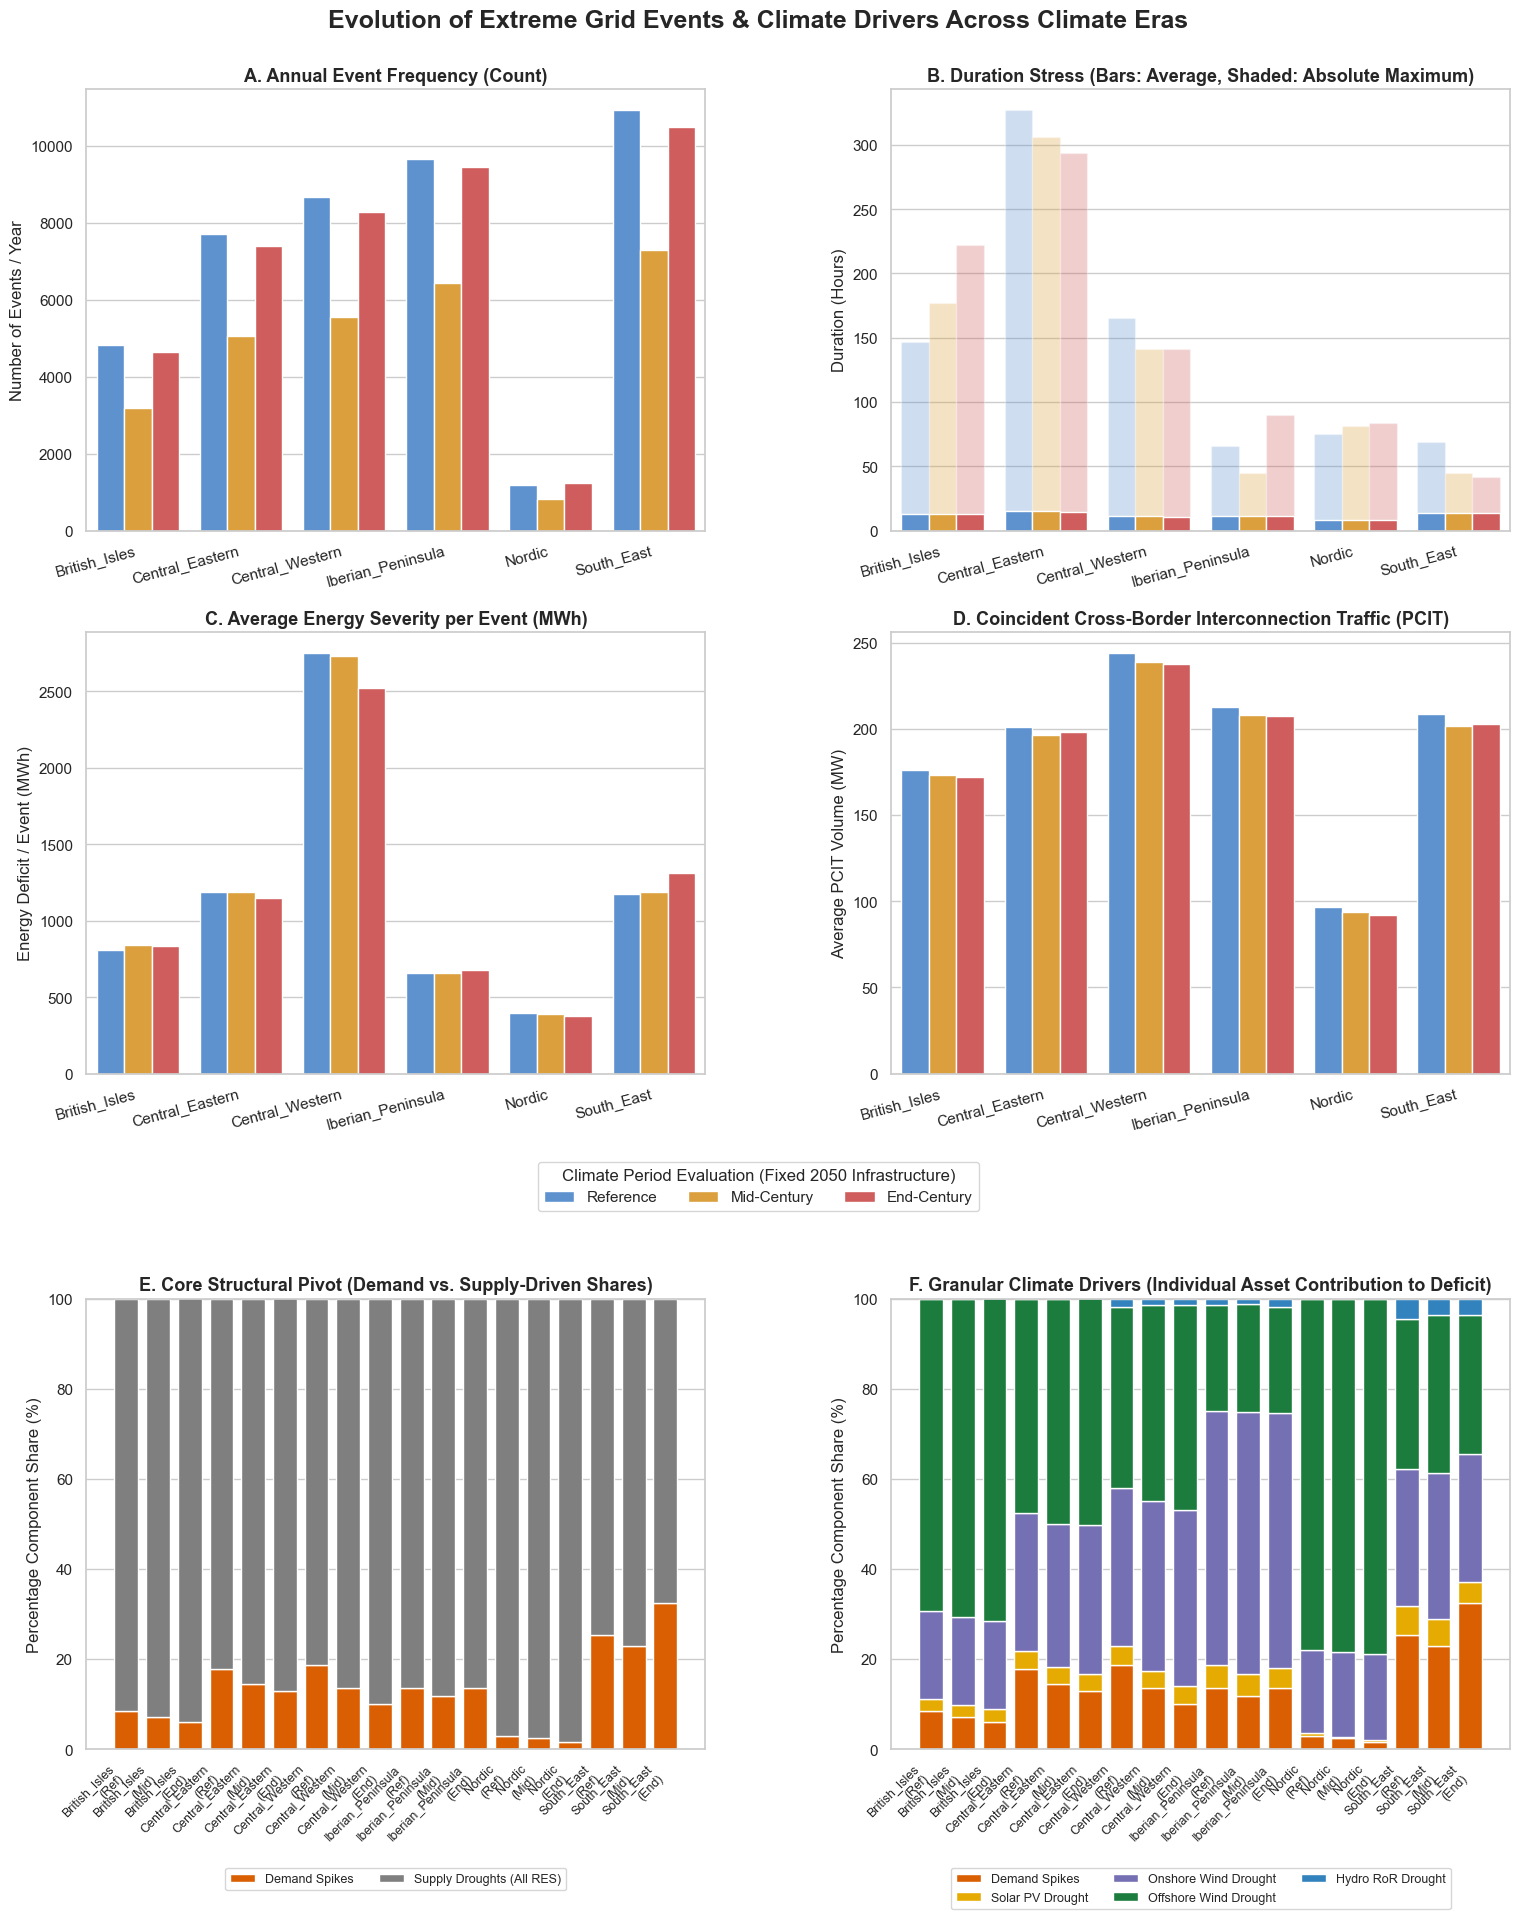

In [138]:
# 3. Generate the analytical plots
fig_dashboard = plot_energy_extreme_metrics_dashboard(df_compiled)
plt.show()

## Extreme behavior

In [139]:
# 1. Compile the multi-period data and compute percentage deltas
df_compiled_extreme, df_percentage_shifts_extreme = compile_and_compare_periods(
    ref_extreme_results, mid_century_extreme_results, end_century_extreme_results
)

In [140]:
# 2. Inspect the raw quantitative values
print("--- RAW QUANTITATIVE DATA ACCROSS ERAS ---")
df_compiled_extreme[
    [
        "Frequency",
        "Avg_Duration_Hours",
        "Max_Duration_Hours",
        "Avg_Energy_Severity_MWh",
        "Avg_PCIT_During_Events_MW",
    ]
].head(18)

--- RAW QUANTITATIVE DATA ACCROSS ERAS ---


Frequency  Avg_Duration_Hours  \
Zone              Period                                         
British_Isles     1_Reference          327            4.623853   
                  2_Mid-Century        249            4.542169   
                  3_End-Century        335            4.334328   
Central_Eastern   1_Reference          403            7.116625   
                  2_Mid-Century        217            6.995392   
                  3_End-Century        225            6.280000   
Central_Western   1_Reference          427            5.676815   
                  2_Mid-Century        238            5.256303   
                  3_End-Century        183            4.655738   
Iberian_Peninsula 1_Reference          649            4.261941   
                  2_Mid-Century        406            4.115764   
                  3_End-Century        639            3.755869   
Nordic            1_Reference           51            5.058824   
                  2_Mid-Century         25            5.640000   
                  3_End-Century         40            5.850000   
South_East        1_Reference          887            4.146561   
                  2_Mid-Century        710            3.701408   
                  3_End-Century       1946            3.561151   

                                 Max_Duration_Hours  Avg_Energy_Severity_MWh  \
Zone              Period                                                       
British_Isles     1_Reference                  30.0               142.476673   
                  2_Mid-Century                15.0               143.686240   
                  3_End-Century                18.0               126.249749   
Central_Eastern   1_Reference                  51.0               143.599487   
                  2_Mid-Century                33.0               135.715450   
                  3_End-Century                30.0               103.322076   
Central_Western   1_Reference                  18.0               448.700695   
                  2_Mid-Century                18.0               366.450662   
                  3_End-Century                18.0               276.496039   
Iberian_Peninsula 1_Reference                  15.0                53.040281   
                  2_Mid-Century                15.0                51.452341   
                  3_End-Century                15.0                39.937100   
Nordic            1_Reference                  15.0                81.620301   
                  2_Mid-Century                24.0               123.962899   
                  3_End-Century                30.0               119.449930   
South_East        1_Reference                  15.0                78.219739   
                  2_Mid-Century                 9.0                65.702400   
                  3_End-Century                 9.0                88.392965   

                                 Avg_PCIT_During_Events_MW  
Zone              Period                                    
British_Isles     1_Reference                   249.789763  
                  2_Mid-Century                 248.221318  
                  3_End-Century                 230.651528  
Central_Eastern   1_Reference                   270.470744  
                  2_Mid-Century                 278.150526  
                  3_End-Century                 277.412827  
Central_Western   1_Reference                   241.854234  
                  2_Mid-Century                 237.332755  
                  3_End-Century                 238.265017  
Iberian_Peninsula 1_Reference                   337.487225  
                  2_Mid-Century                 330.778677  
                  3_End-Century                 307.368350  
Nordic            1_Reference                   113.178967  
                  2_Mid-Century                  96.167825  
                  3_End-Century                 127.247623  
South_East        1_Reference                   302.897333  
             

In [141]:
print("--- PERCENTAGE SHIFTS FROM REFERENCE PERIOD (%) ---")
df_percentage_shifts_extreme

--- PERCENTAGE SHIFTS FROM REFERENCE PERIOD (%) ---


,Frequency_Mid_Change_%,Frequency_End_Change_%,Avg_Duration_Hours_Mid_Change_%,Avg_Duration_Hours_End_Change_%,Max_Duration_Hours_Mid_Change_%,Max_Duration_Hours_End_Change_%,Total_Annual_Energy_Severity_MWh_Mid_Change_%,Total_Annual_Energy_Severity_MWh_End_Change_%,Avg_Energy_Severity_MWh_Mid_Change_%,Avg_Energy_Severity_MWh_End_Change_%,Demand_Driven_Share_%_Mid_Change_%,Demand_Driven_Share_%_End_Change_%,PV_Driven_Share_%_Mid_Change_%,PV_Driven_Share_%_End_Change_%,Wind_Onshore_Driven_Share_%_Mid_Change_%,Wind_Onshore_Driven_Share_%_End_Change_%,Wind_Offshore_Driven_Share_%_Mid_Change_%,Wind_Offshore_Driven_Share_%_End_Change_%,Hydro_RoR_Driven_Share_%_Mid_Change_%,Hydro_RoR_Driven_Share_%_End_Change_%
Zone,,,,,,,,,,,,,,,,,,,,
British_Isles,-23.9,2.4,-1.8,-6.3,-50.0,-40.0,-23.2,-9.2,0.8,-11.4,-21.1,-21.1,0.0,-16.7,-4.5,-2.5,4.0,3.6,0.0,0.0
Central_Eastern,-46.2,-44.2,-1.7,-11.8,-35.3,-41.2,-49.1,-59.8,-5.5,-28.0,-23.3,-34.4,22.2,11.1,3.6,6.3,6.2,8.8,0.0,0.0
Central_Western,-44.3,-57.1,-7.4,-18.0,0.0,0.0,-54.5,-73.6,-18.3,-38.4,-18.1,-49.5,50.0,-16.7,4.5,13.5,6.4,17.0,-33.3,-60.0
Iberian_Peninsula,-37.4,-1.5,-3.4,-11.9,0.0,0.0,-39.3,-25.9,-3.0,-24.7,-15.8,-18.4,25.0,25.0,1.0,-0.3,8.5,11.9,-25.0,25.0
Nordic,-51.0,-21.6,11.5,15.6,60.0,100.0,-25.6,14.8,51.9,46.3,-24.4,-48.8,-33.3,0.0,-3.8,1.9,2.5,2.1,0.0,0.0
South_East,-20.0,119.4,-10.7,-14.1,-40.0,-40.0,-32.8,147.9,-16.0,13.0,-6.0,68.5,25.0,-25.0,1.0,-34.0,4.7,-30.0,-16.0,44.0


<string>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


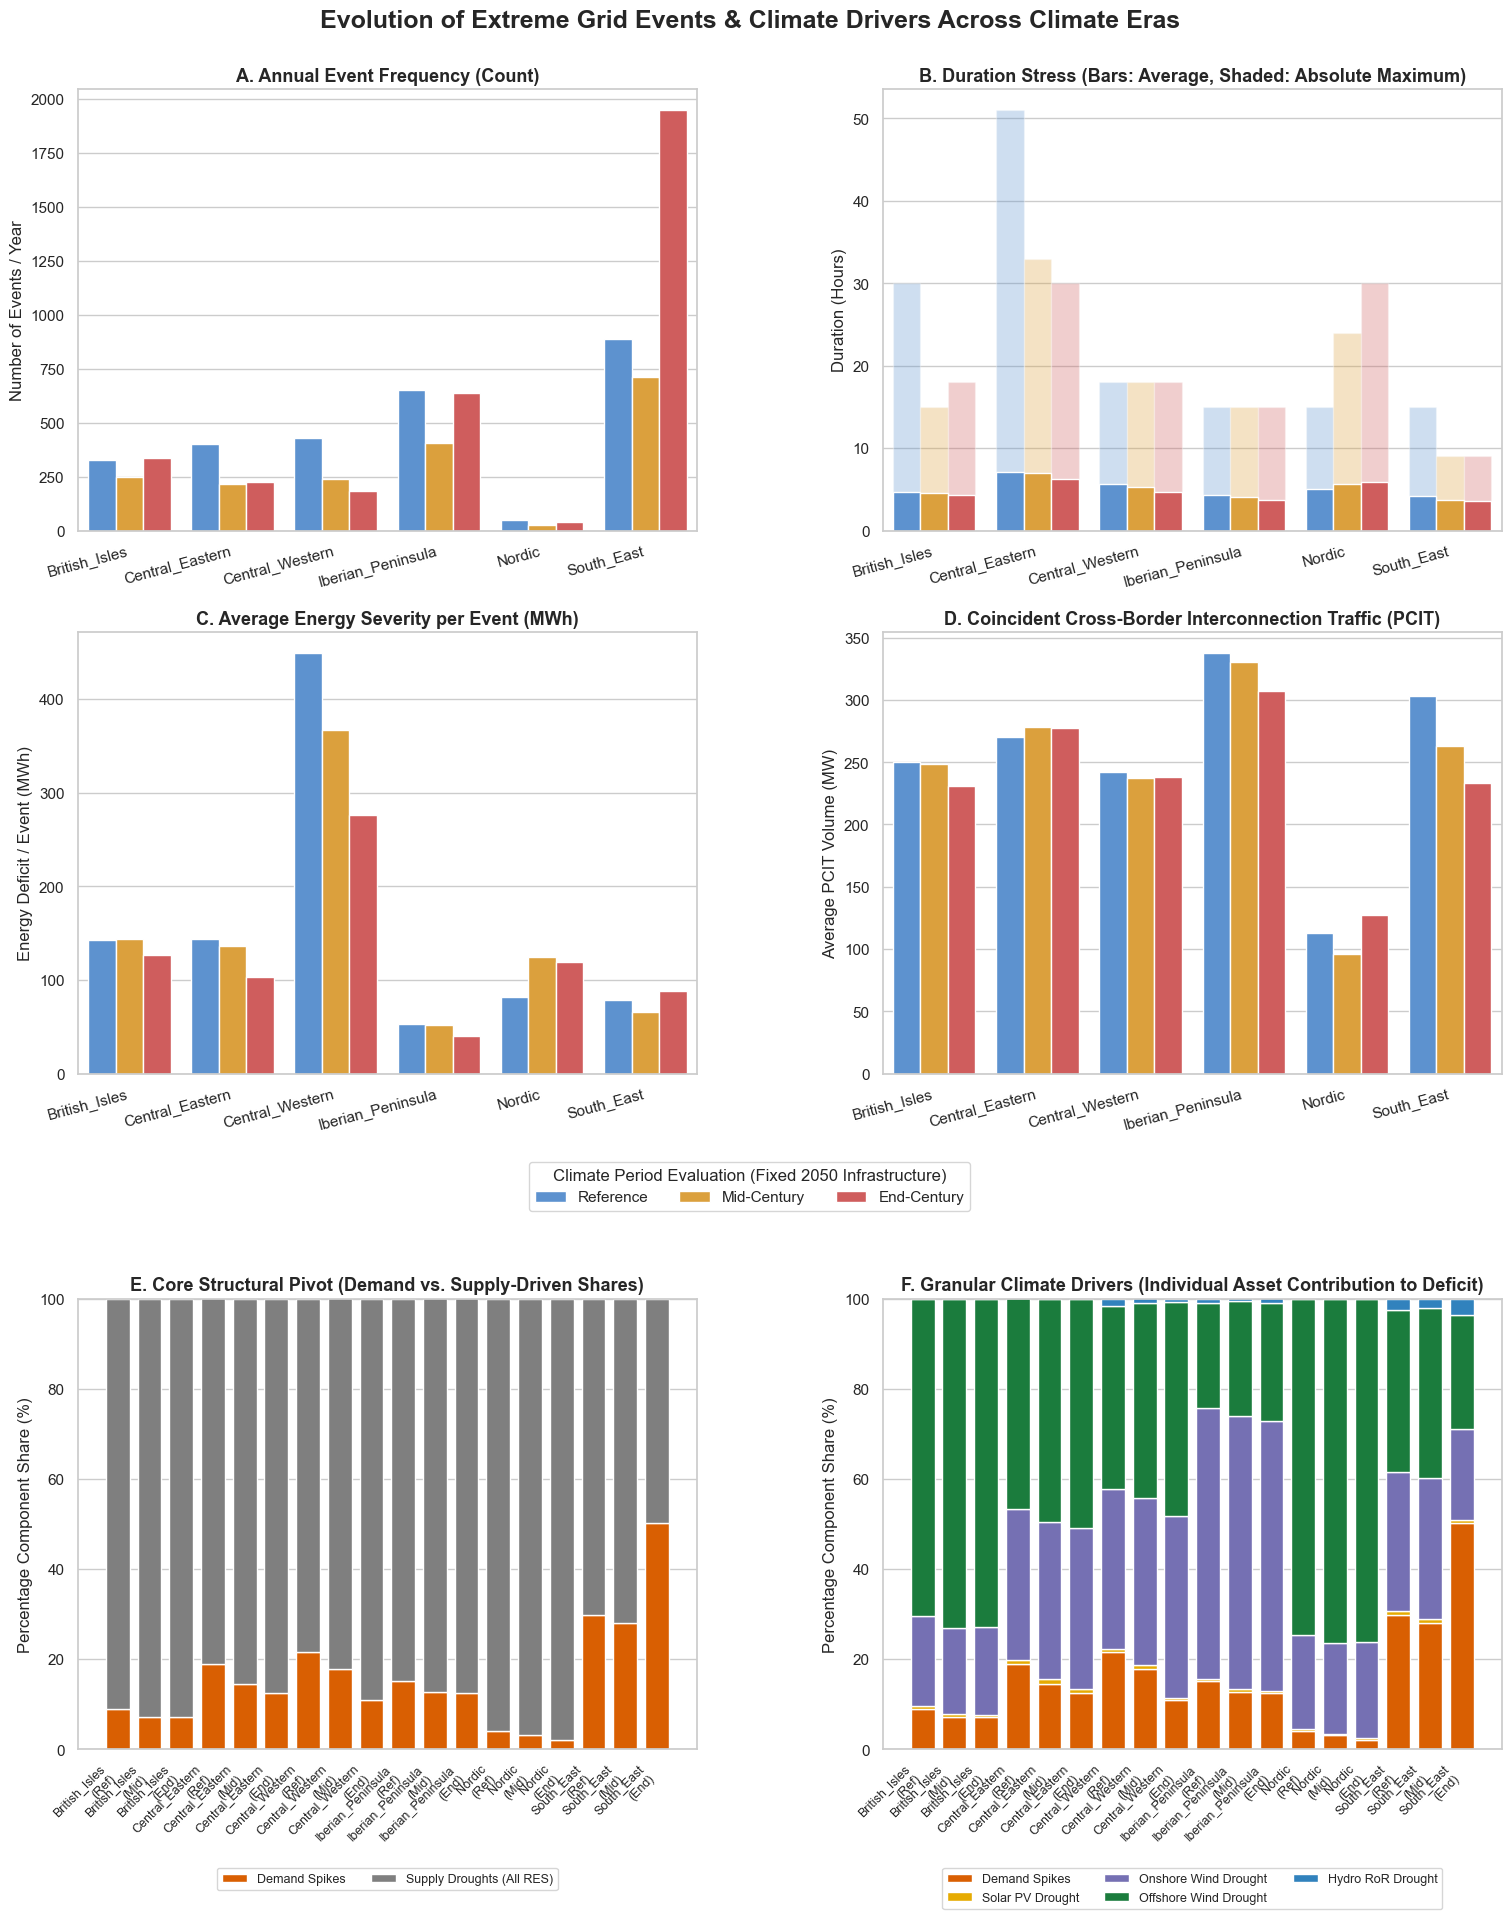

In [142]:
# 3. Generate the analytical plots
fig_dashboard = plot_energy_extreme_metrics_dashboard(df_compiled_extreme)
plt.show()